# A Comparative Study of Sentiment Analysis: FinBERT vs LLama-3.1

Over the past decade, LLMs such as BERT (Devlin et al., 2019), FinBERT (Araci, 2019), RoBERTa (Liu et al., 2019), GPT (Brown et al., 2020), OPT (Zhang et al., 2022) and LLaMA (Touvron et al., 2023) have consistenly proved superior over the traditional lexicon-based sentiment models. Among these, FinBERT, a BERT base model fine-tuned on financial text, is particularly popular due to its relatively small size (110 million parameters).

However, FinBERT has known limitations such as insensitivity to numerical values as well as deteoriorating performace with sentence complexity. Put simply, FinBERT is adept at detecting tone and language but lacks the reasoning to understand potential impact on stock markets.

Thus, for a potential analyst who wants to identify key themes, changing expectations and the drivers of a bank's performance, FinBERT may prove inadequate. Consequently, for a temporal RAG pipeline to benefit from FinBERT's speed, its performance needs to be improved.

A significant improvement in sentiment classification performance is typically achieved through building upon FinBERT's architecture via hybridisation with an LLM. Since the hybridisation approach involves targeted fine-tuning, for a set of earnings call transcripts that are unlabelled we instead propose an agentic flow that still utilises zero-shot classification such as the one below:

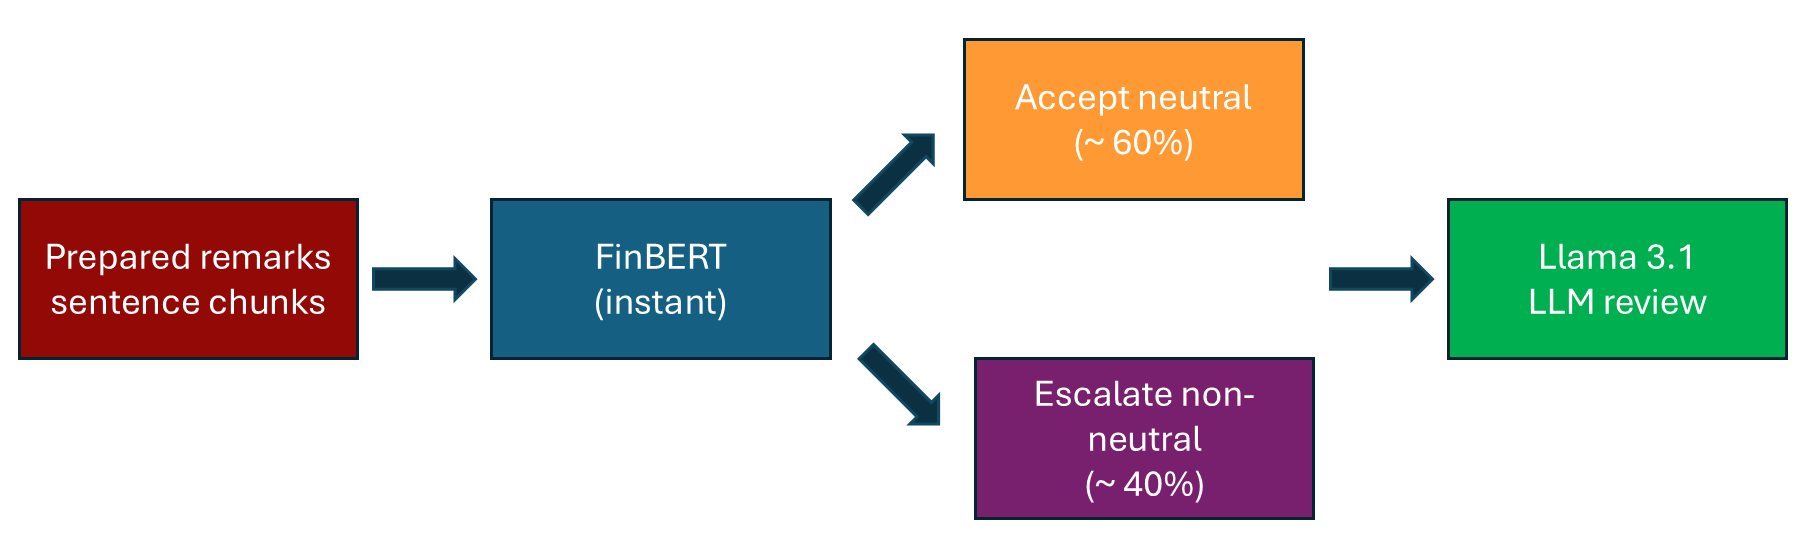

Note the flow illustrated above is based on FinBERT showing the highest agreement level for neutral statements during domain training (Araci, 2019).

Before a RAG system can be developed, however, the performance of FinBERT needs to be analysed against the LLM, in this case, Llama 3.1 8B Instruct. Therefore, the current study focusses on the prepared remarks section of the quarterly earnings call transcripts, to compare and contrast performance of FinBERT against the Llama 3.1 model.

The outline of the study is as follows:

* First, the prepared remarks section is segregated to account for the nuances between CFO and CEO remarks.

* Next, the prepared remarks by each speaker is processed into 5-sentence chunks to achieve granularity without losing context.

* A zero-shot sentiment classification is performed by the (static) Llama 3.1 model while recording its reasoning behind each label.

* The LLM is also used to extract the primary topic discussed in a given 5-sentence chunk.

* The LLM classification is then followed by zero-shot classification using FinBERT where the confidence score for a given label is also recorded.

* Finally, the results are visualised and compared.


##1.1 Import relevant libraries.

In [ ]:
!pip install pandas PyArrow

In [ ]:
import os
from google.colab import files
from pathlib import Path
import pandas as pd
import numpy as np
import random
import tensorflow as tf
import re
import nltk
from nltk.tokenize import sent_tokenize
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from collections import Counter
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.cluster import AgglomerativeClustering

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

**Hugging Face & FinBERT Transformer Pipelines**

In [ ]:
!pip install -q transformers accelerate bitsandbytes huggingface_hub pipeline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 62.0 MB/s eta 0:00:00


In [ ]:
import torch
from google.colab import userdata
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig, pipeline
from transformers import GenerationConfig
from sentence_transformers import SentenceTransformer
from datasets import Dataset

In [ ]:
# Authenticate Hugging Face
from google.colab import userdata
from huggingface_hub import login
try:
    huggingface_token = userdata.get("HF_TOKEN")
except userdata.SecretNotFoundError:
    raise RuntimeError("Add your Hugging Face token to Colab Secrets as HF_TOKEN and enable notebook access before running this cell.")

login(token=huggingface_token)

**Ensuring reproducability and clearing cache:**

In [ ]:
# Function to control stochastic behaviour when model tuning
def set_random_seed(seed_val):
   # Set the `PYTHONHASHSEED` environment variable at a fixed value
    os.environ['PYTHONHASHSEED']=str(seed_val)
    # Set the `python` built-in pseudo-random generator at a fixed value
    np.random.seed(seed_val)
    # Set the `numpy` pseudo-random generator at a fixed value
    random.seed(seed_val)
    # Set the `tensorflow` pseudo-random generator at a fixed value
    tf.random.set_seed(seed_val)

In [ ]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.empty_cache()

In [ ]:
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
Device Name: NVIDIA A100-SXM4-40GB


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
set_random_seed(42)

## 1.2 Load the CSV input file.

**DISCLAIMER**

The preprocessing steps involved in creating the input CSV file and the file itself have been excluded from the current notebook to avoid potential copy right infringement issues.

The quarterly earnings call transcripts themselves are publicly available.

In [ ]:
prepared_remarks_combined_df = pd.read_csv("prepared_remarks_compact_input.csv")

In [ ]:
print(prepared_remarks_combined_df.shape)
prepared_remarks_combined_df.info()

(115, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   document_id    115 non-null    object
 1   call_id        115 non-null    object
 2   bank           115 non-null    object
 3   year           115 non-null    int64 
 4   quarter        115 non-null    object
 5   fiscal_period  115 non-null    object
 6   speaker_name   115 non-null    object
 7   speaker_role   115 non-null    object
 8   speaker_turn   115 non-null    int64 
 9   verbatim_text  115 non-null    object
dtypes: int64(2), object(8)
memory usage: 9.1+ KB


In [ ]:
prepared_remarks_combined_df

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text
0,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Paul Donofrio,CFO,4,"Thanks, Brian. Good morning, and hello, everyo..."
1,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Brian Moynihan,CEO,3,"Thank you, Lee, and thank all of you for joini..."
2,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Brian Moynihan,CEO,3,Good morning. And thank all of you for joining...
3,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Paul Donofrio,CFO,4,"Thanks, Brian. Hello, everyone. I'm starting o..."
4,doc_abc71b3bf815c8a1,BAC_2021Q3_earnings_call,BAC,2021,Q3,2021-Q3,Brian Moynihan,CEO,3,"Thank you, Lee (ph). And good morning to all, ..."
...,...,...,...,...,...,...,...,...,...,...
110,doc_671c70b3c9d6bc3d,JPM_2025Q1_earnings_call,JPM,2025,Q1,2025-Q1,Jeremy Barnum,CFO,2,"Thank you and good morning, everyone. Starting..."
111,doc_720ee28f1fa395e2,JPM_2025Q2_earnings_call,JPM,2025,Q2,2025-Q2,Jeremy Barnum,CFO,2,"Thank you very much and good morning, everyone..."
112,doc_4f2f83015473a1b4,JPM_2025Q3_earnings_call,JPM,2025,Q3,2025-Q3,Jeremy Barnum,CFO,2,"Thank you, and good morning, everyone. Let me ..."
113,doc_40b732e278c14d17,JPM_2025Q4_earnings_call,JPM,2025,Q4,2025-Q4,Jeremy Barnum,CFO,3,"At the top of the page, we provided a reconcil..."


Note the bank labels stand for:

* BAC: Bank of America Corporation
* CITI: Citigroup
* JPM: JPMorgan Chase & Co

## 1.3 For each executive remark, count the number of sentences and figures quoted.

In [ ]:
# Define a financial pattern for dollars ($10, $5.4B) and percentages (12%, 5 percent)
fin_pattern = r'(?:\$\d+(?:,\d{3})*(?:\.\d+)?(?:\s?[bB]illion|\s?[mM]illion)?|\b\d+(?:\.\d+)?\s?(?:%|percent)\b)'
# Count the number of financial metrics/figures quoted by the management excluding dates
prepared_remarks_combined_df['figure_count'] = prepared_remarks_combined_df["verbatim_text"].apply(lambda x: len(re.findall(fin_pattern, str(x))))

# Count sentences using NLTK tokenization
prepared_remarks_combined_df['sentence_count'] = prepared_remarks_combined_df["verbatim_text"].apply(lambda x: len(sent_tokenize(str(x))) if pd.notnull(x) else 0)


## 1.4 Preprocessing the prepared remarks excerpts.

Traditional preprocessing approaches like removing stop words or lowercasing text is likely to worsen a transformer-based model's performance, for most LLMs naturally rely on the exact context as well as punctuation to determine sentiment accurately. Therefore, it is adequate to remove potential HTML tags.

In [ ]:
# Strip potential HTML tags from the column
prepared_remarks_combined_df['cleaned_verbatim_text']=prepared_remarks_combined_df["verbatim_text"].str.replace(r'<[^<>]*>', '', regex=True)

In [ ]:
prepared_remarks_combined_df.head()

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text,figure_count,sentence_count,cleaned_verbatim_text
0,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Paul Donofrio,CFO,4,"Thanks, Brian. Good morning, and hello, everyo...",66,163,"Thanks, Brian. Good morning, and hello, everyo..."
1,doc_7c89fe76bbded96f,BAC_2021Q1_earnings_call,BAC,2021,Q1,2021-Q1,Brian Moynihan,CEO,3,"Thank you, Lee, and thank all of you for joini...",0,11,"Thank you, Lee, and thank all of you for joini..."
2,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Brian Moynihan,CEO,3,Good morning. And thank all of you for joining...,14,108,Good morning. And thank all of you for joining...
3,doc_cfcb930e840aa34f,BAC_2021Q2_earnings_call,BAC,2021,Q2,2021-Q2,Paul Donofrio,CFO,4,"Thanks, Brian. Hello, everyone. I'm starting o...",25,174,"Thanks, Brian. Hello, everyone. I'm starting o..."
4,doc_abc71b3bf815c8a1,BAC_2021Q3_earnings_call,BAC,2021,Q3,2021-Q3,Brian Moynihan,CEO,3,"Thank you, Lee (ph). And good morning to all, ...",15,104,"Thank you, Lee (ph). And good morning to all, ..."


## 2.1 EDA: How many speaking turns CEO and CFO takes over the years? How many figures (e.g. net income, total revenue, operating expenses) does the CFO disclose over the quarters?  

The first impressions of the transcript data suggests there is an inbalance in the number of appearances between a CEO and a CFO which is worth noting.

In [ ]:
# Extract number of appearances
executive_appearance_counts=prepared_remarks_combined_df.groupby(['bank','year'])["speaker_role"].value_counts()


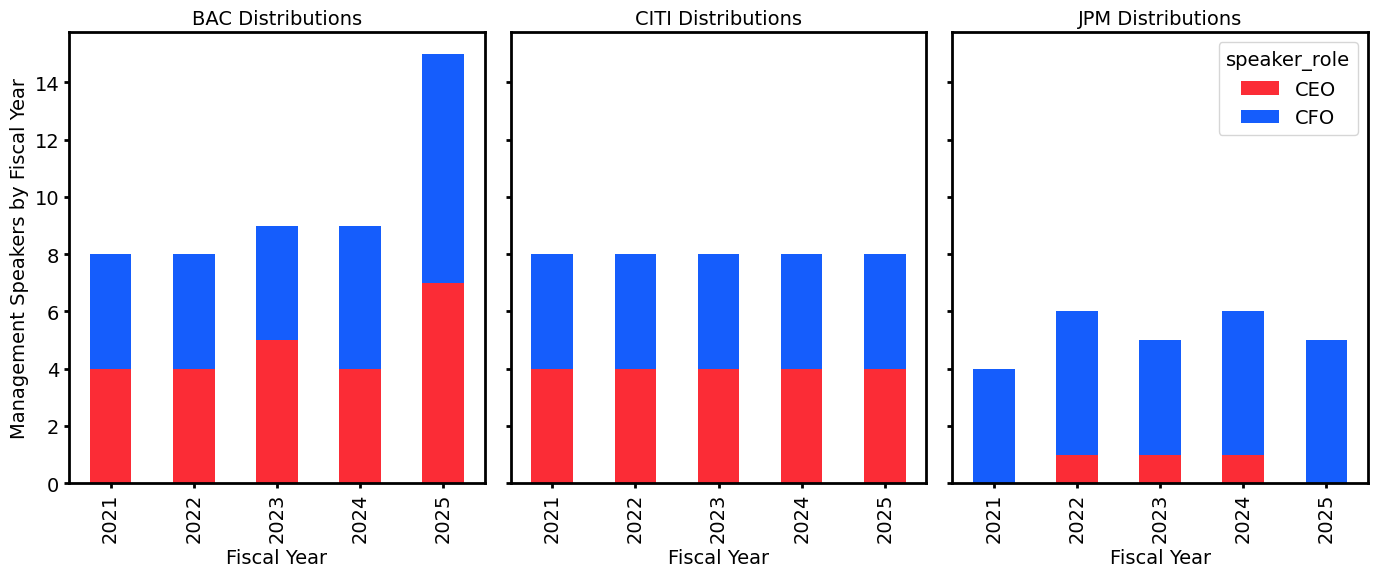

In [ ]:
# Compare Attendance : CFO vs CEO
fig, axes = plt.subplots(1, 3, figsize=(14,6),sharey=True)

speaker_colors = {'CFO': '#155DFC','CEO': '#FB2C36'}
titles=['BAC Distributions', 'CITI Distributions','JPM Distributions']
# Fill missing combinations with 0
BAC_appearance_counts=executive_appearance_counts.BAC.unstack(fill_value=0)
CITI_appearance_counts=executive_appearance_counts.CITI.unstack(fill_value=0)
JPM_appearance_counts=executive_appearance_counts.JPM.unstack(fill_value=0)

# Plot as a stacked or grouped bar chart
BAC_appearance_counts.plot(kind='bar', stacked=True, color=speaker_colors,ax=axes[0])
CITI_appearance_counts.plot(kind='bar', stacked=True,color=speaker_colors,ax=axes[1])
JPM_appearance_counts.plot(kind='bar', stacked=True, color=speaker_colors,ax=axes[2])

for i in range(3):
  axes[i].set_xlabel('Fiscal Year',fontsize=14)
  axes[i].set_title(titles[i],fontsize=14)
  axes[i].set_ylabel('Management Speakers by Fiscal Year',fontsize=14)
  axes[i].tick_params(width=2)
  for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

# plt.ylabel('Management Distributions by Fiscal Year')
plt.tight_layout()
# Remove the unnecessary legends
axes[0].get_legend().remove()
axes[1].get_legend().remove()
plt.savefig('SpeakerDists.svg')
plt.show()

The histogram plots suggests the inbalance is the most extereme for JPMorgan. In contrast, the Citigroup appears to have an exceptionally well balance between the remarks made by the CEOs and CFOs. The presence of a balanced speaking turns between the two executives is also evident in the case of Bank of America.

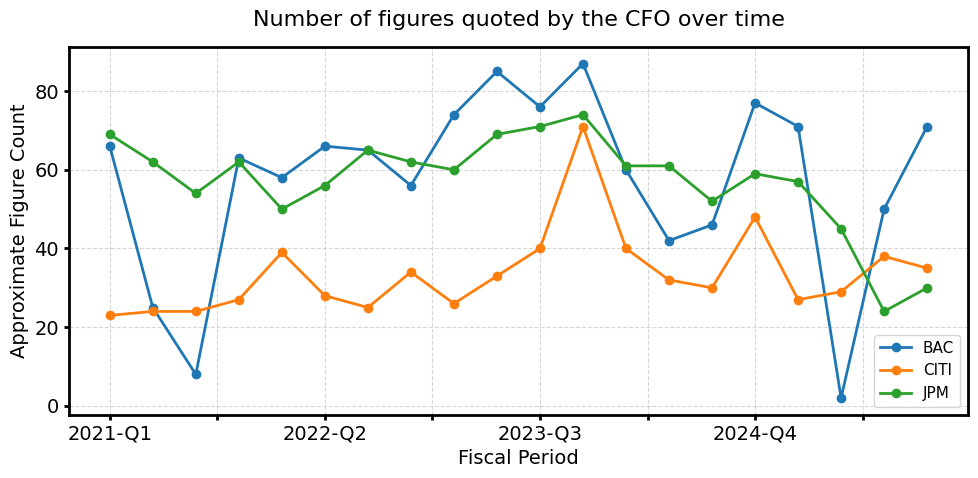

In [ ]:
# Inspect the number of figures quoted by a CFO over the years

# Filter for Speaker Role
prepared_remarks_combined_CFO = (prepared_remarks_combined_df[prepared_remarks_combined_df['speaker_role']=='CFO']
                               .groupby(['bank','fiscal_period'])['figure_count']
                               .sum())
# BAC CFO
BAC_fig_counts_CFO = prepared_remarks_combined_CFO.BAC
# CITI CFO
CITI_fig_counts_CFO = prepared_remarks_combined_CFO.CITI
# JPM CFO
JPM_fig_counts_CFO = prepared_remarks_combined_CFO.JPM

# Plots
plt.figure(figsize=(10, 5))
BAC_fig_counts_CFO.plot(kind='line', marker='o',linewidth=2, label='BAC')
CITI_fig_counts_CFO.plot(kind='line', marker='o', linewidth=2,label='CITI')
JPM_fig_counts_CFO.plot(kind='line', marker='o', linewidth=2,label='JPM')
# Axes Labels
plt.title('Number of figures quoted by the CFO over time',fontsize=16,pad=15)
plt.xlabel('Fiscal Period',fontsize=14)
plt.ylabel('Approximate Figure Count',fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)  # a subtle background grid for quarter tracking
plt.tight_layout()

# Axes appearance
axes = plt.gca()
# current_ylim = axes.get_ylim()
# axes.set_ylim(current_ylim[0], current_ylim[1] * 1.3
axes.tick_params(width=2)
# Change spine (axis line) thickness
for edge in ['top', 'bottom', 'left', 'right']:
    axes.spines[edge].set_linewidth(2)
# plt.savefig(filename)
plt.legend(loc='lower right', fontsize=11)
plt.savefig('FiguresQuoted.svg')
plt.show()

Across all 3 banks, there are notable fluctions between the number of figures a CFO quotes over the fiscal quarters. While the fluctuations does not seem to present with a seasonal pattern, the trends may be used to asses whether there are overlaps between the periods where the CFO sentiment becomes increasingly negative and those where less figures are quoted.

## 2.1 Process remarks text into chunks of 5 sentences.

* Chunking allows the LLMs to evaluate the sentiment of individual, localized statement in a more nuanced way.
* Moroever, dissecting the large prepared remarks excerpts, that are multiple pages long at times, into smaller segments ensures that no data, financial metrics, or key sentiment indicators are lost or ignored.
* Most importantly, it by-passes strict truncation limits for the context window:

For instance, FinBERT has a hard maximum context window of 512 tokens - the max size of Bert Token. While this is on the order of 128,000 tokens for the Llama model, it is important to capture nuance and ensure a direct comparison such that we can track the reasoning behind the classifications made by Llama.

In [ ]:
# Helper function to group text into chunks of 5 sentences
def chunk_text(text, chunk_size=5):
    if not isinstance(text, str):
        return []

    # Split text into individual sentences
    sentences = nltk.sent_tokenize(text)

    # Group sentences into blocks of 5 and rejoin them into strings
    chunks = [
        " ".join(sentences[i:i + chunk_size])
        for i in range(0, len(sentences), chunk_size)
    ]
    return chunks

The chosen sentence cluster size is 5 which is an odd number and can help sway the sentiment towards a more definitive positive or negative, after assessing each sentence (i.e. help with the generation of logit probabilities). Moreover, we can more easily track the decisions made by the Llama model, especially when it comes to neutral labels.

In [ ]:
# Create a temporary column containing the list of chunks
prepared_remarks_combined_df['sentence_chunks'] = prepared_remarks_combined_df['cleaned_verbatim_text'].apply(lambda x: chunk_text(x, chunk_size=5))


In [ ]:
# Explode the rows
prepared_remarks_chunked_df = prepared_remarks_combined_df.explode('sentence_chunks').reset_index(drop=True)

In [ ]:
# Track the sequence of chunks per conversation
prepared_remarks_chunked_df ['chunk_index'] = prepared_remarks_chunked_df.groupby(['call_id','speaker_role']).cumcount() + 1

## 3.1 The LLM pipeline set-up and labelling.

The chosen model is the **Llama 3.1 8B Instruct** developed by Meta (arXiv:2407.21783 [cs.AI]). It is an auto-regressive language model that uses an optimized transformer architecture and has been tuned using reinforcement learning with human feedback (RLHF) to align with human preferences.

Since the sentence chunks are extracted from the unlabelled prepared remarks section of the earnings call transcripts, a 'RLHF-trained' model helps brdige the gap between zero-shot classificaton and supervised learning which would realy on domain expert labelling.

Another advantage of the Llama 3.1 8B Instruct model is that it can be configured with 4-bit quantization to reduce memory usage.

The straight forward Hugging Face pipeline set-up which allows batch processing is another bonus that helps with practicality.

In [ ]:
# Load the Hugging Face Pipeline
hf_token = userdata.get('HF_TOKEN')

# Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

model_id = "meta-llama/Llama-3.1-8B-Instruct"

# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_id, token=hf_token)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=quantization_config,
    device_map="auto",
    token=hf_token
)

# Clear inherited hub configurations to supress future warnings
model.generation_config.temperature = None  # Removes the default temperature
model.generation_config.top_p = None        # Removes the default top_p
model.generation_config.max_length = None   # Prevents legacy length alerts

# Initialize text generation pipeline cleanly
llama_pipeline = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
)


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

In [ ]:
# Function to batch extract sentiment using an LLM pipeline

def batch_analyze_earnings_llm(dataset, text_column, batch_size=8):
    """
    Processes the entire dataframe column efficiently in batches on the GPU.
    """
    def sentiment_generator():
        for row in dataset:
            yield [
                {"role": "system", "content": (
                    "You are an expert financial analyst. Analyze the following earnings call transcript excerpt. "
                    "Determine the overall sentiment (Positive, Negative, or Neutral) and provide a short one-sentence rationale highlighting key financial drivers mentioned. "
                    "Format your output exactly as:\nSentiment: [Sentiment]\nRationale: [Your rationale]"
                )},
                {"role": "user", "content": f"Transcript Excerpt:\n\"\"\"{row[text_column]}\"\"\""}
            ]

    # Define the pad token ID, for the pipeline to batch sequences together:
    # ======================================================
    # Grab just the primary integer out of the Llama 3 multiple-EOS list
    if isinstance(llama_pipeline.model.config.eos_token_id, list):
        primary_eos_id = llama_pipeline.model.config.eos_token_id[0]
    else:
        primary_eos_id = llama_pipeline.model.config.eos_token_id
    # Override properties using a single integer value
    llama_pipeline.tokenizer._special_tokens_map["pad_token"] = llama_pipeline.tokenizer.eos_token
    llama_pipeline.tokenizer.init_kwargs["pad_token"] = llama_pipeline.tokenizer.eos_token

    # Inject the single integer ID to satisfy the strict configuration dataclass
    llama_pipeline.model.config.pad_token_id = primary_eos_id
    llama_pipeline.tokenizer.pad_token_id = primary_eos_id


    # Create a clean Generation Configuration to prevent parameter conflicts
    generation_config = GenerationConfig(
        max_new_tokens=150,
        do_sample=False,      # Enables greedy decoding
        max_length=None,      # Wipes the default legacy length limitation
        # Note: 'temperature' is omitted entirely since do_sample=False
    )

    # Run pipeline in parallel batches
    pipeline_outputs = llama_pipeline(
        sentiment_generator(),
        batch_size=batch_size,
        generation_config=generation_config,
        clean_up_tokenization_spaces=False
    )

    return [out[0]["generated_text"] for out in pipeline_outputs]


In [ ]:
# For batch processing convert to Hugging Face datasets
prepared_remarks_hf_dataset = Dataset.from_pandas(prepared_remarks_chunked_df[["sentence_chunks"]])


In [ ]:
prepared_remarks_hf_dataset


Dataset({
    features: ['sentence_chunks'],
    num_rows: 2268
})

In [ ]:
# Batch process the data set
prepared_remarks_llm_output=batch_analyze_earnings_llm(prepared_remarks_hf_dataset,'sentence_chunks', batch_size=8)

In [ ]:
# Parse the outputs using regex in a list comprehension
def llm_output_parser(output):
  sentiments = []
  reasonings = []

  for message_list in output:
      # Extract the raw string content from the final assistant message
      if isinstance(message_list, list) and len(message_list) > 0:
          raw_text = message_list[-1]["content"]
      else:
          raw_text = str(message_list) # Fallback just in case

      # Run regex searches on the actual string text
      sentiment_match = re.search(r"Sentiment:\s*(Positive|Negative|Neutral)", raw_text, re.IGNORECASE)
      rationale_match = re.search(r"Rationale:\s*(.*)", raw_text, re.IGNORECASE)

      sentiments.append(sentiment_match.group(1).strip() if sentiment_match else "Unknown")
      reasonings.append(rationale_match.group(1).strip() if rationale_match else raw_text.strip())

  return sentiments, reasonings


Assign the final parsed lists back to the prepared remarks data frame:

In [ ]:
# The LLM labels and reasoning output
prepared_remarks_chunked_df['llm_sentiment'] = llm_output_parser(prepared_remarks_llm_output)[0]
prepared_remarks_chunked_df['llm_reasoning'] = llm_output_parser(prepared_remarks_llm_output)[1]

## 3.2 Topic Extraction with the Llama 3.1 8B Instruct model:

To understand the main themes behind the labels associated with the 5-sentence chunks, it is useful to perform a basic topic extraction from each row.

In [ ]:
# Update the LLM extraction pipeline to extract topics:
def batch_extract_topics_llm(dataset, text_column, batch_size=8):
    """
    Processes the entire dataset in batches to extract the primary topic
    from each earnings call transcript excerpt.
    """
    # Handle Llama 3 multiple-EOS configuration as before
    if isinstance(llama_pipeline.model.config.eos_token_id, list):
        primary_eos_id = llama_pipeline.model.config.eos_token_id[0]
    else:
        primary_eos_id = llama_pipeline.model.config.eos_token_id

    # Apply the padding configuration overrides
    llama_pipeline.tokenizer.pad_token = llama_pipeline.tokenizer.eos_token
    llama_pipeline.tokenizer.pad_token_id = primary_eos_id
    llama_pipeline.model.config.pad_token_id = primary_eos_id

    def topic_generator():
      for row in dataset:
          messages = [
              {
                  "role": "system",
                  "content": (
                      "You are a strict financial API. Analyze the text and classify it into exactly ONE topic category "
                      "(e.g., Revenue Growth, Supply Chain Logistics, Macroeconomic Headwinds, CapEx Spending, R&D Investment). "
                      "Respond with ONLY the category name. Do not include newlines, bullet points, introductory text, or explanations."
                  )
              },
              # Structure the user input cleanly with clear boundaries
              {"role": "user", "content": f"Text to classify:\n{row[text_column]}\n\nClassification label:"}
          ]
          yield llama_pipeline.tokenizer.apply_chat_template(
              messages, tokenize=False, add_generation_prompt=True
          )

    # Lower max_new_tokens to 10 for a single topic title.
    # This physically stops the model from printing a long list.
    generation_config = GenerationConfig(
        max_new_tokens=10,
        do_sample=False,
        pad_token_id=primary_eos_id,
        eos_token_id=primary_eos_id
    )

    pipeline_outputs = llama_pipeline(
        topic_generator(),
        batch_size=batch_size,
        generation_config=generation_config,
        clean_up_tokenization_spaces=False,
        return_full_text=False
    )

    # Extract text, split by newline, grab ONLY the first line, then strip 'assistant'
    return [
        out[0]["generated_text"].split("\n")[0].replace("assistant", "").strip()
        for out in pipeline_outputs
    ]


In [ ]:
# Batch process the data set to extract topics
prepared_remarks_llm_topics=batch_extract_topics_llm(prepared_remarks_hf_dataset,'sentence_chunks', batch_size=8)

In [ ]:
# Pass and store in the working data frame
prepared_remarks_chunked_df['primary_topic']=prepared_remarks_llm_topics

In [ ]:
torch.cuda.empty_cache()

## 3.3 FinBERT pipeline set-up and zero-shot sentiment classification:

FinBERT provides a specialized sentiment analysis model fine-tuned specifically on financial texts to automatically classify the sentiment of earnings call transcript chunks. It serves as the baseline sentiment classifier whose performance, trends, and negative tone detections are analyzed across different banks, fiscal periods, and speaker roles. Finally, its predictions are directly compared against the larger Llama-3.1 model to benchmark its accuracy, strengths, and limitations in a financial context.

In [ ]:
# Load original pre-trained FinBERT
model_name = 'ProsusAI/finbert'
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Map model outputs to labels
labels_map = {0: 'negative', 1: 'neutral', 2: 'positive'}


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

In [ ]:
# Function to perform FinBERT inference

def run_finbert_inference(dataset, text_column='sentence_chunks', batch_size=8, model=model, tokenizer=tokenizer, device=device, labels_map=labels_map):

    print(f"Running inference on {len(dataset)} chunks...")
    model.eval()

    # Define the batch processing function for dataset.map
    def batch_inference(batch):
        # Tokenize the batch of text
        inputs = tokenizer(
            batch[text_column],
            truncation=True,
            padding=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        # Disable gradient calculation, only running inference - not training
        with torch.no_grad():
            outputs = model(**inputs) # unpack the token IDs and attention masks
            # scale the raw logits into a clean probability distribution
            probs = torch.softmax(outputs.logits, dim=-1)
            # extract the actual prediction by finding the highest probability
            conf_scores, pred_indices = torch.max(probs, dim=-1)

        # Return new columns to be appended to the dataset
        output = {
            "predicted_sentiment": [labels_map[idx.item()] for idx in pred_indices],
            "confidence_score": conf_scores.cpu().numpy().tolist()
        }
        return output

    # Run mapping and drop of original columns
    predictions_dataset = dataset.map(
        batch_inference,
        batched=True,
        batch_size=batch_size,
        remove_columns=dataset.column_names
    )

    return predictions_dataset


In [ ]:
finbert_predictions_dataset=run_finbert_inference(dataset=prepared_remarks_hf_dataset, text_column='sentence_chunks', batch_size=8)

Running inference on 2268 chunks...


Map:   0%|          | 0/2268 [00:00<?, ? examples/s]

In [ ]:
finbert_predictions_df=finbert_predictions_dataset.to_pandas()
finbert_predictions_df

,predicted_sentiment,confidence_score
0,neutral,0.587821
1,negative,0.872497
2,negative,0.491427
3,negative,0.914233
4,negative,0.885652
...,...,...
2263,negative,0.958015
2264,negative,0.864524
2265,negative,0.960625
2266,positive,0.779977


In [ ]:
# Assign the predictions to the working data frame
prepared_remarks_chunked_df['predicted_sentiment'] = finbert_predictions_df['predicted_sentiment']
prepared_remarks_chunked_df['confidence_score'] = finbert_predictions_df['confidence_score']

In [ ]:
# Freeze the output
prepared_remarks_chunked_df.to_csv('prepared_remarks_labelled_output.csv',index=False)

## 4.1 Visualisation and (qualitative) analysis of the LLM sentiment label distributions across the 3 banks.

Check for unsual labels and clean-up the dataset:

In [ ]:
prepared_remarks_chunked_df[prepared_remarks_chunked_df['llm_sentiment']=='Unknown']

,document_id,call_id,bank,year,quarter,fiscal_period,speaker_name,speaker_role,speaker_turn,verbatim_text,figure_count,sentence_count,cleaned_verbatim_text,sentence_chunks,chunk_index,llm_sentiment,llm_reasoning,primary_topic,predicted_sentiment,confidence_score
591,doc_258784ec82dacef3,BAC_2023Q3_earnings_call,BAC,2023,Q3,2023-Q3,Brian Moynihan,CEO,3,"Good morning, everyone, and thank you for join...",25,151,"Good morning, everyone, and thank you for join...",Alastair?,31,Unknown,I don't see any financial data or key drivers ...,Macroeconomic Headwinds,positive,0.849169
948,doc_feb1737cc6a784dc,BAC_2025Q2_earnings_call,BAC,2025,Q2,2025-Q2,Alastair Borthwick,CFO,4,"It was a little lower than last quarter, drive...",2,6,"It was a little lower than last quarter, drive...","Please, Chloe.",2,Unknown,It seems there is not enough information to an...,Macroeconomic Headwinds,positive,0.878040


Since the number of sentences within each transcript excerpts were not always perfectly divisible into 5 sentence chunks, there appears to be some very short stray sentences that do not provide any context.

The Llama 3.1 8B Instruct model successfully captures these by labelling them with an 'Unknown' sentiment. Meanwhile, FinBERT labels these non-sentences as positive.

In [ ]:
prepared_remarks_chunked_df['sentence_chunks'][591]

'Alastair?'

In [ ]:
prepared_remarks_chunked_df['sentence_chunks'][948]

'Please, Chloe.'

In [ ]:
# Filter out rows where the target column is 'Unknown'
prepared_remarks_chunked_df = prepared_remarks_chunked_df[prepared_remarks_chunked_df['llm_sentiment'] != 'Unknown']

While we have intentionally chose a hard 5-sentence macro-structure to flag issues such as those listed above, it is worth considering a sliding-window approach (i.e. with a 10–20% overlap) as a future improvement.

In [ ]:
# Helper function to group by period and bank and sort by role
def get_label_counts(df, roles=['CEO', 'CFO'], groupby_cols=['bank', 'fiscal_period'], target_col='llm_sentiment', normal='True'):
    """
    Filters a dataframe by specific speaker roles and calculates either the
    normalized or raw value counts of a target column grouped by specified columns.
    -----
    Returns: A dictionary where the keys are the roles and the values are the resulting series.
    """
    results = {}
    for role in roles:
        # Filter, group by multiple columns, and calculate normalized value counts for the variable column
        counts = (
            df[df['speaker_role'] == role]
            .groupby(groupby_cols)[target_col]
            .value_counts(normalize=normal)
        )
        results[role] = counts
    return results


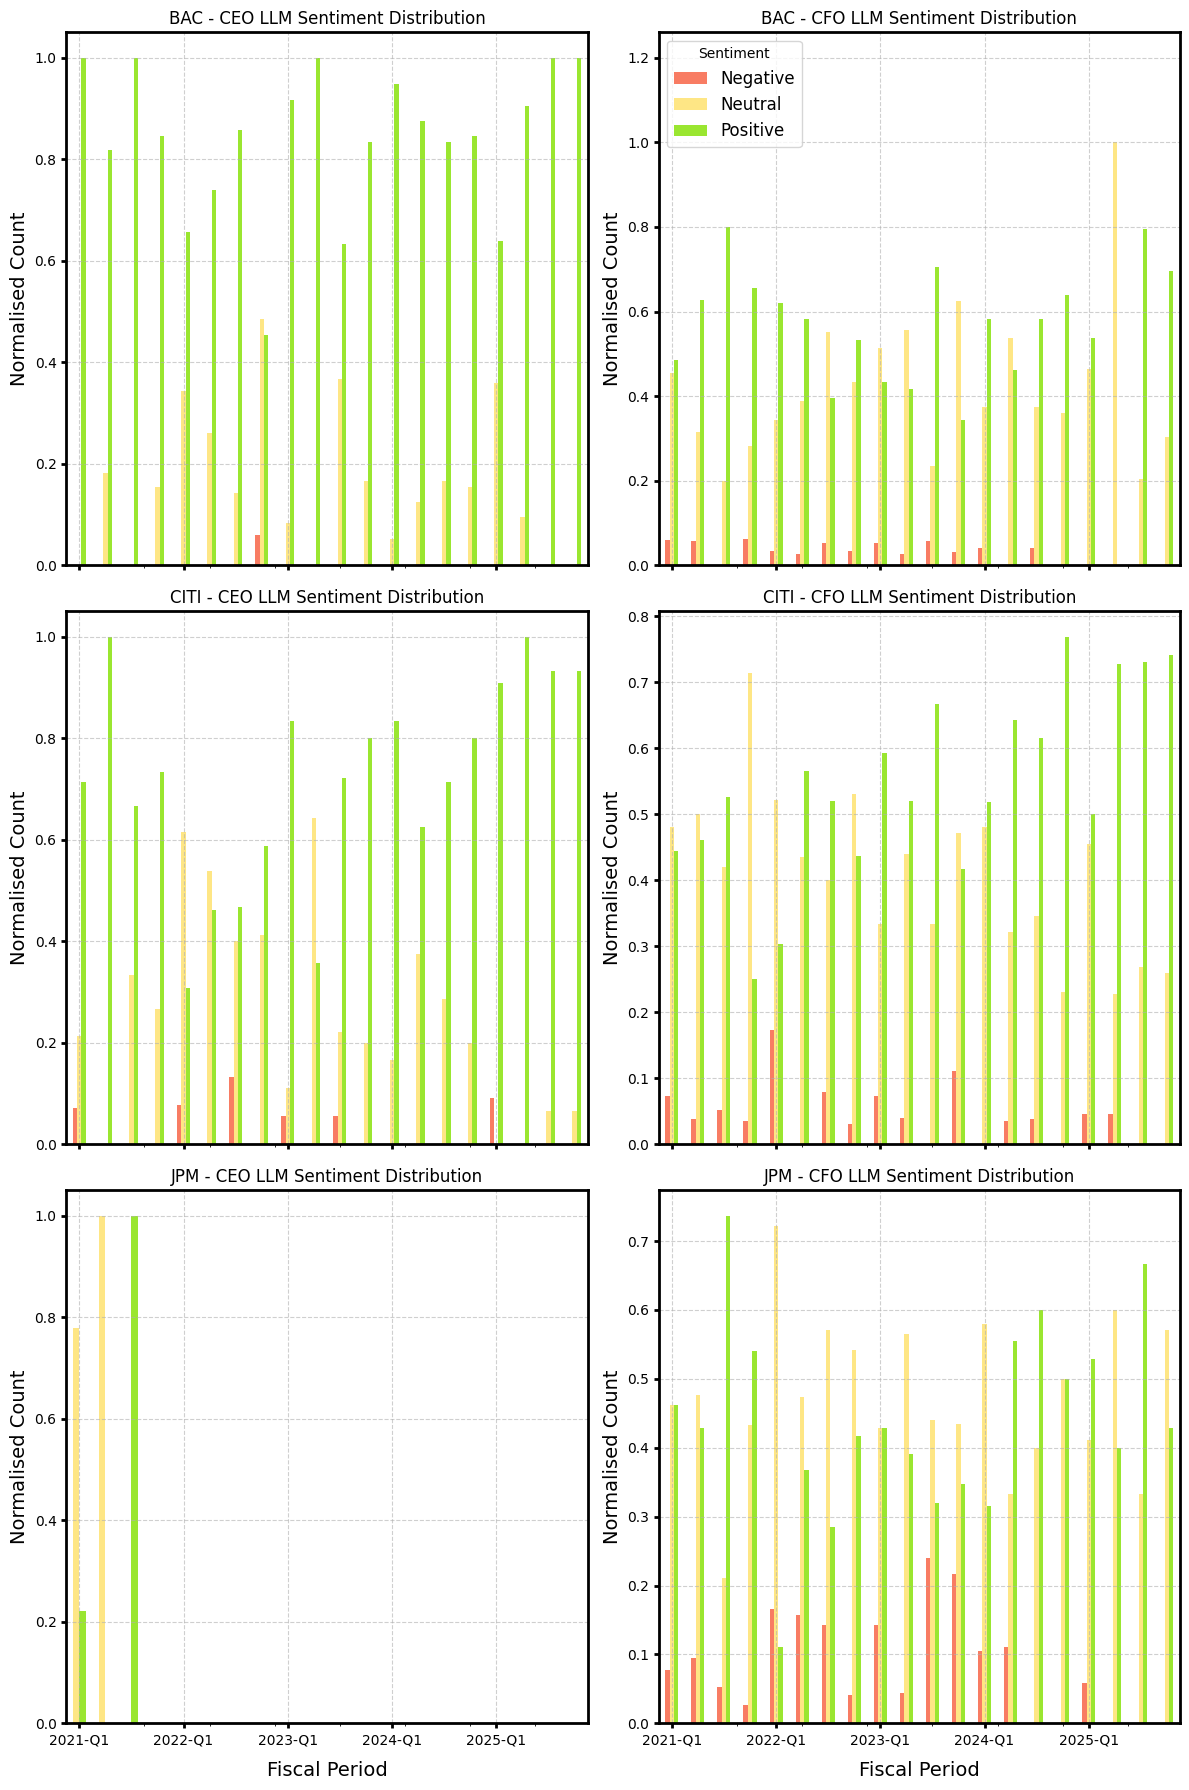

In [ ]:
# Distribution plots

# Get the normalised LLM label counts
llm_counts_norm=get_label_counts(prepared_remarks_chunked_df)

roles = ['CEO', 'CFO']
banks = ['BAC','CITI','JPM']
sentiment_colors = {
    'Positive': '#9AE630',  # Green
    'Neutral': '#FEE685',   # Yellow
    'Negative': '#F87C63'   # Red
}

# Create a 3-row by 2-column figure grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 18), sharex=True)

# Loop through banks and roles to plot
for col_idx, role in enumerate(roles):
    for row_idx, bank in enumerate(banks):

        # Select the specific subplot axis
        ax = axes[row_idx, col_idx]

        # Get the specific series data (unstacking makes it easy to plot lines/bars per sentiment)
        plot_data = llm_counts_norm[role][bank].unstack(fill_value=0)

        # Plot the data (e.g., as a line plot or stacked bar)
        plot_data.plot(kind='bar',color=sentiment_colors, ax=ax, rot=0)

        # Titles and Formatting
        ax.set_title(f"{bank} - {role} LLM Sentiment Distribution")
        ax.set_ylabel("Normalised Count",fontsize=14)
        ax.set_xlabel("Fiscal Period",fontsize=14,labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.6)

        # Increase tick visibility
        ax.tick_params(width=2)
        ax.tick_params(axis='y', labelsize=10)
        ax.tick_params(axis='x', labelsize=10)


        # Change spine (axis line) outline thickness to 2
        for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

        ax.grid(True, linestyle='--', alpha=0.6)

        # Get current ticks and labels
        ticks = ax.get_xticks()
        labels = [label.get_text() for label in ax.get_xticklabels()]

        # Apply every 4th tick and label
        ax.set_xticks(ticks[::4])
        ax.set_xticklabels(labels[::4], rotation=0)

        # Only show the legend on the very first plot to avoid cluttering the grid
        if row_idx == 0 and col_idx == 1:
            ax.legend(title='Sentiment', loc='upper left', fontsize=12)
            # Expand the y-axis limit by 20% to safely accommodate the legends
            current_ylim = ax.get_ylim()
            ax.set_ylim(current_ylim[0], current_ylim[1] * 1.2)
        else:
            ax.legend().remove()

# Clean up layout and display
plt.tight_layout()
# plt.savefig('LLM_Label_Dists.svg')
plt.show()

Across all 3 banks and both executives, the distribution of the labels assigned by the Llama 3.1 8B Instruct model are overwhelmingly positive or neutral with the proportion of negative labels rarely reaching beyong 20%. In the case of Bank of America, CitiGroup and JPMorgan CFOs the maximum negative proportion is on around 5%, 17% and 23%, respectively.

Comparing the CEO to CFO sentiments, it can be ascertained that there are more cases of negative sentiment in CFO speeches compared that of the CEOs.

Below are some examples of the reasoning used by the Llama 3.1 model to label the 5-sentence chunks:

In [ ]:
prepared_remarks_chunked_df[['llm_sentiment','llm_reasoning']].sample(5)

,llm_sentiment,llm_reasoning
1522,Neutral,The company is focusing on cost reduction and ...
113,Positive,The CFO's departure is framed as a positive op...
1871,Positive,The company reported a 20% year-on-year revenu...
2029,Negative,The overall sentiment is negative due to the s...
162,Positive,The company is experiencing a shift towards di...


In [ ]:
# Neutral
prepared_remarks_chunked_df.loc[1522,'llm_reasoning']

'The company is focusing on cost reduction and expense optimization strategies to drive investment revenue, indicating a cautious approach to managing expenses and improving profitability.'

In [ ]:
# Positive
print(prepared_remarks_chunked_df.loc[113,'llm_reasoning'])

# Positive
print(prepared_remarks_chunked_df.loc[1871,'llm_reasoning'])

The CFO's departure is framed as a positive opportunity for the company, highlighting the CFO's past success and the company's future growth prospects.
The company reported a 20% year-on-year revenue increase, driven by higher management fees, growth in deposit and loan balances, and investment valuation gains, despite deposit margin compression and rising expenses.


In [ ]:
# Negative
prepared_remarks_chunked_df.loc[2029,'llm_reasoning']

'The overall sentiment is negative due to the significant decline in Investment Banking revenue and fees across various business segments, despite some market conditions being in line with expectations.'

As the examples show the reasoning used to label the sentiments is reasonable and similar to human reasoning.

However, in the neutral case, the mention of cost reduction and expense optimisation could also be considered negative without the strategic context. In other words, *the company taking a cautious approach towards improving profits but being careful in a volatile market* is not necessarily negative and the LLM appears to account for the hidden context.

In the first positive case, correspoding to row '113', the remarks made about the CFO departure could also be taken negative but is clearly given a positive spin by the speaker. One would need to have intimate knowledge of the sector and the specific bank to know whether this is truly positive or negative.

Without going through each small paragraph and doing additonal research using external resources, the LLM reasoning remains sensible and valid.

## 4.2 Visualisation and analysis of the FinBERT sentiment label distributions obtained for the 3 banks.

To visualize the sentiment trends over time, we will convert the categorical predictions (`positive` -> 1, `neutral` -> 0, `negative` -> -1) into a continuous sentiment score. We will then group the data by bank, year, and quarter to plot these trends.

In [ ]:
# Map sentiments to numerical values
sentiment_mapping = {'positive': 1.0, 'neutral': 0.0, 'negative': -1.0}
prepared_remarks_chunked_df['sentiment_score'] = prepared_remarks_chunked_df['predicted_sentiment'].map(sentiment_mapping)

In [ ]:
# prepared_remarks_chunked_df.head()

### 4.2.1 Average Quarterly Sentiment Trends Over Time (FinBERT)

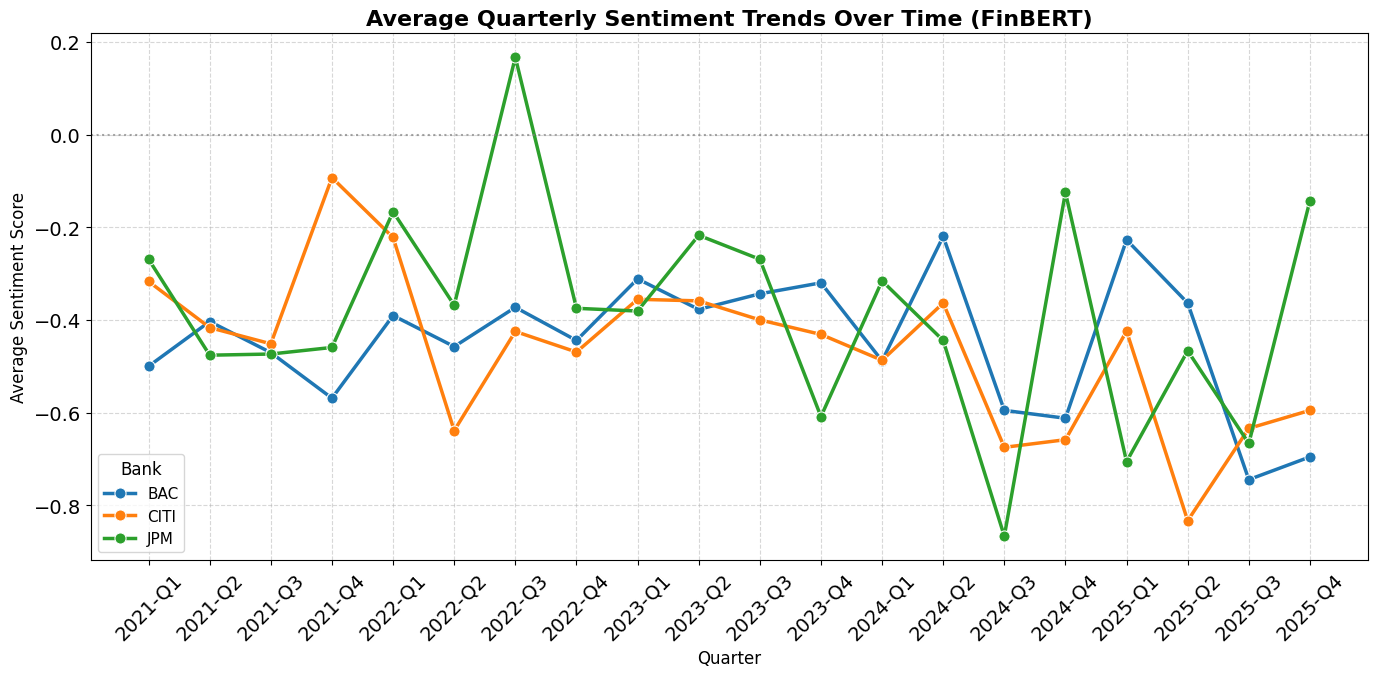

In [ ]:
# Group by Bank and Period, then calculate the average sentiment score
confidence_trend= prepared_remarks_chunked_df.groupby(['bank','fiscal_period'])['sentiment_score'].mean().reset_index()

# Sort chronologically by year and quarter
confidence_trend = confidence_trend.sort_values(by=['bank', 'fiscal_period']).reset_index(drop=True)

# Plot the sentiment trends
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=confidence_trend,
    x='fiscal_period',
    y='sentiment_score',
    hue='bank',
    marker='o',
    linewidth=2.5,
    markersize=8
)

plt.title('Average Quarterly Sentiment Trends Over Time (FinBERT)', fontsize=16, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Average Sentiment Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.axhline(0, color='gray', linestyle=':', alpha=0.7)
plt.legend(title='Bank', fontsize=11, title_fontsize='12')
plt.tight_layout()
# plt.savefig('Ave_Quarterly_Sent_Trends.svg')
plt.show()

**Overall Negative Baseline Sentiment**: Virtually all quarterly average sentiment scores across the three banks (Bank of America Corporation, Citigroup, JPMorgan) reside below 0 (the neutral axis), staying primarily between -0.2 and -0.8. The negative skew is typical for corporate financial disclosures. In regulatory filings and transcripts, language is highly conservative, focusing on risks, cost containment, allowances for credit losses, and macro uncertainties, which financial sentiment models like FinBERT categorize as 'negative'.


### 4.2.2 Yearly Trends of Sentiments: CEO vs CFO by Bank

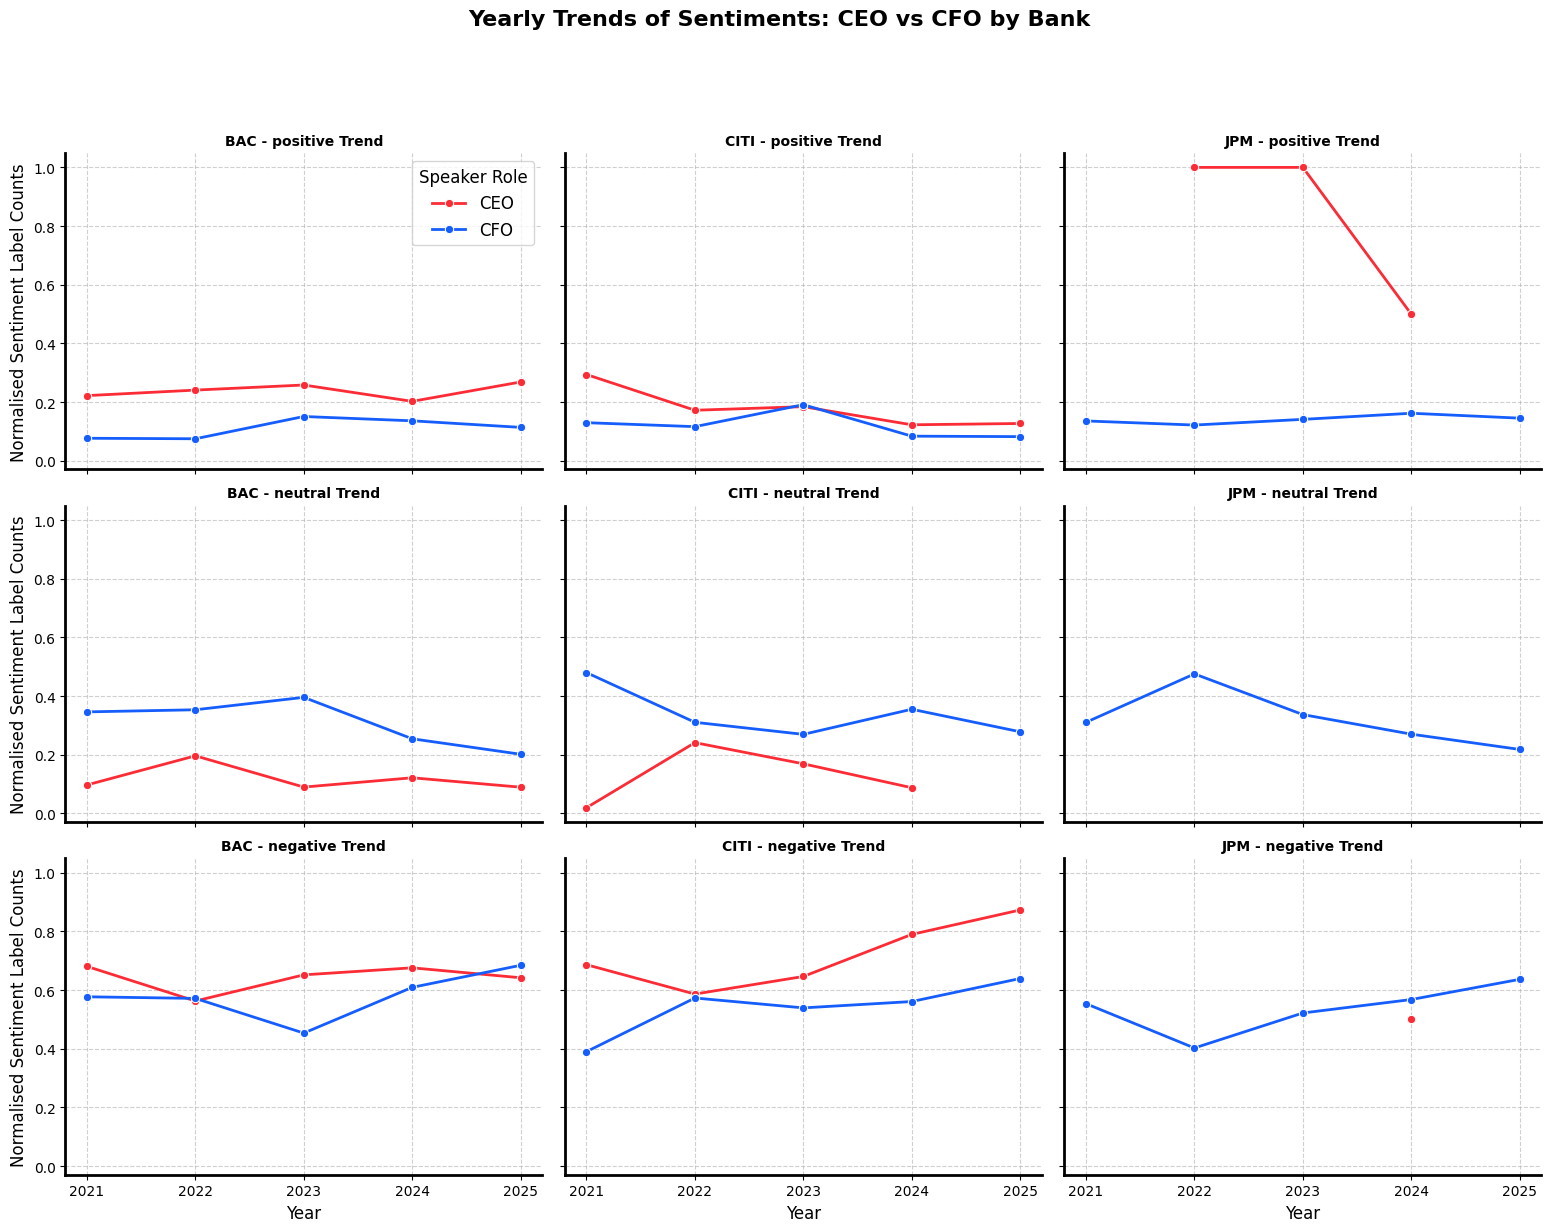

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

finbert_counts_year= get_label_counts(prepared_remarks_chunked_df,
                                      groupby_cols=['bank', 'year'],
                                      target_col='predicted_sentiment', normal='True')


finbert_counts_year_df = (pd.DataFrame(finbert_counts_year).stack()
                         .reset_index()
                         .rename(columns={"level_3": "speaker_role", 0: "proportion"})
                        )


# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    finbert_counts_year_df,
    row="predicted_sentiment",
    col="bank",
    hue="speaker_role",
    palette=speaker_colors,
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"]
)

g.map(sns.lineplot, "year", "proportion", marker="o", linewidth=2, markersize=6)

# Style layout and labels
g.set_axis_labels("Year", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the first axis subplot from the grid array
first_ax = g.axes.flat[0]

# Apply the legend constraints directly to this specific axis
first_ax.legend(
    title="Speaker Role",
    fontsize=12,
    title_fontsize=12,
    loc="upper right"
)

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(sorted(finbert_counts_year_df['year'].unique()))
    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Yearly Trends of Sentiments: CEO vs CFO by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Yearly_Sent_Trends_Bank.svg')
plt.show()

The observations are consistent with the expectation that CEOs tend to deliver strategic, future-oriented, and vision-focused narratives, which contain a higher concentration of positive sentiment, whereas CFOs focus on structural facts.

In the top row (positive Trend), the red line (CEOs) is almost always positioned higher than the red line (CFOs) for both BAC and CITI. At JPM, the CEO trend is at its most extreme contrasting the JPM's CFO trend, grouped under 20% positive.

In the middle row (neutral Trend), the blue line (CFOs) sits consistently and significantly above the red line (CEOs) across all three banks. The observation is consistent with the typical CFO communication pattern: parsing regulatory details, tax adjustments, accounting guidelines, and balance sheet reconciliation items that convey zero emotional/strategic tilt.

In the bottom row (negative Trend), both executives have a high proportion of negative chunks (regularly between 40% and 80%). Because financial sentiment models like FinBERT categorize terms like "cost", "expense", "risk", and "decline" as negative, standard banking discourse naturally skews.


### 4.2.3 Quarterly Trends of Sentiments: CEO vs CFO by Bank

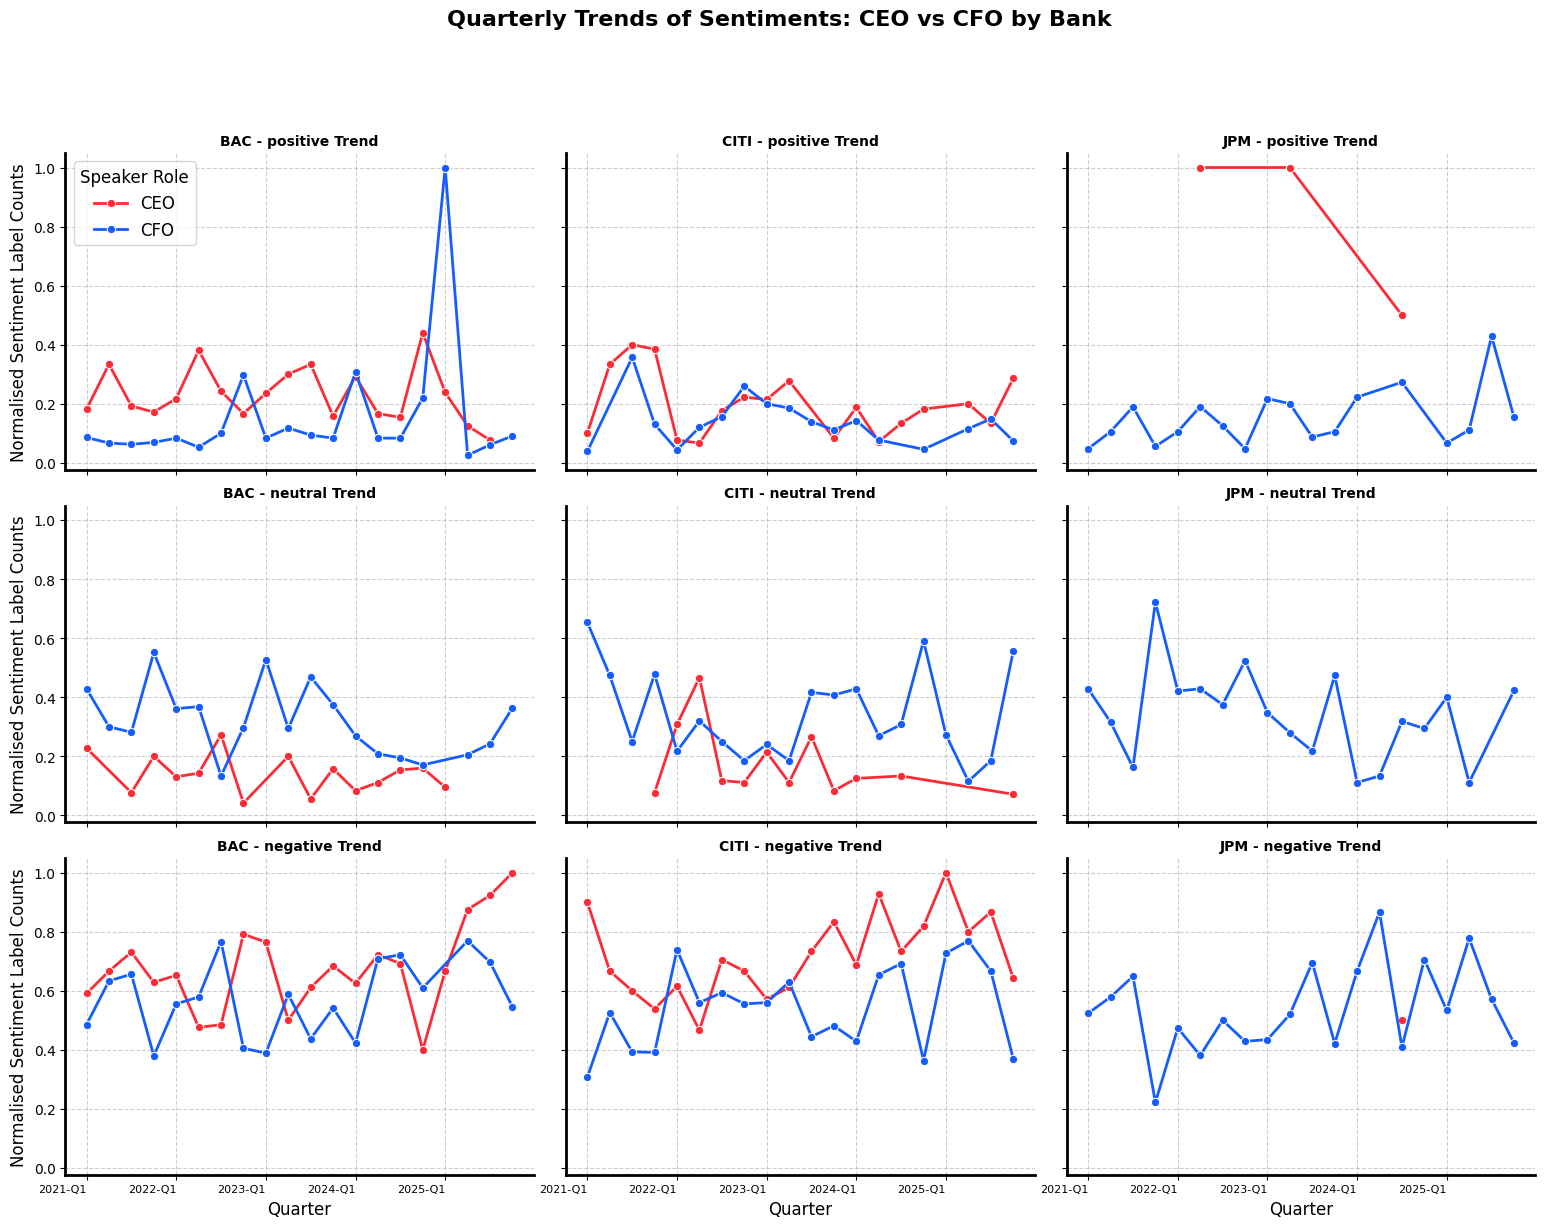

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

finbert_counts_quarter= get_label_counts(prepared_remarks_chunked_df,
                                      groupby_cols=['bank', 'fiscal_period'],
                                      target_col='predicted_sentiment', normal='True')


finbert_counts_quarter_df =(pd.DataFrame(finbert_counts_quarter)
                            .stack().reset_index()
                            .rename(columns={"level_3": "speaker_role", 0: "proportion"})
                           )

# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    finbert_counts_quarter_df,
    row="predicted_sentiment",
    col="bank",
    hue="speaker_role",
    palette=speaker_colors,
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"]
)

g.map(sns.lineplot, "fiscal_period", "proportion", marker="o", linewidth=2, markersize=6)

# Style layout and labels
g.set_axis_labels("Quarter", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the first axis subplot from the grid array
first_ax = g.axes.flat[0]

# Apply the legend constraints directly to this specific axis
first_ax.legend(
    title="Speaker Role",
    fontsize=12,
    title_fontsize=12,
    loc="upper left"
)
chronological_quarters = sorted(finbert_counts_quarter_df['fiscal_period'].unique())

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(range(len(chronological_quarters)))
    ax.set_xticklabels(chronological_quarters, rotation=45, ha='right', fontsize=8)
    # Get current ticks and labels
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ax.get_xticklabels()]

    # Apply every 4th tick and label
    ax.set_xticks(ticks[::4])
    ax.set_xticklabels(labels[::4], rotation=0)

    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Quarterly Trends of Sentiments: CEO vs CFO by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Quarterly_Sent_Trends_Bank.svg')
plt.show()


While the yearly plots present a smoother, gradual change, the quarterly curves reveal sharp, immediate reactions to macro events and earnings shocks. An example is the massive positive sentiment spike experienced by BAC around 2025-Q2- after the event causing it dissipates the spike course corrects over the next quarter and plummets to below 10%.

Across all three banks, the CFOs' blue lines in the neutral and negative rows show a remarkably steady, structural baseline. CFOs rarely fall below a 40% negative or 20% neutral concentration in any given quarter. This is because their updates focus on the recurring granular, objective financial results, expenses, and provisions.






### 4.2.4 Negative Sentiment Trend by Bank per Quarter


The negative sentiment distribution plot isolates the proportion of sentence chunks classified as negative per quarter, providing a direct view of defensive positioning over time. Since the CEO does not always speak/take part in the earnings calls, in cases where they speak once during the call with a negative underlying sentiment, the percentage can blow up to 100%, skewing the dataset.

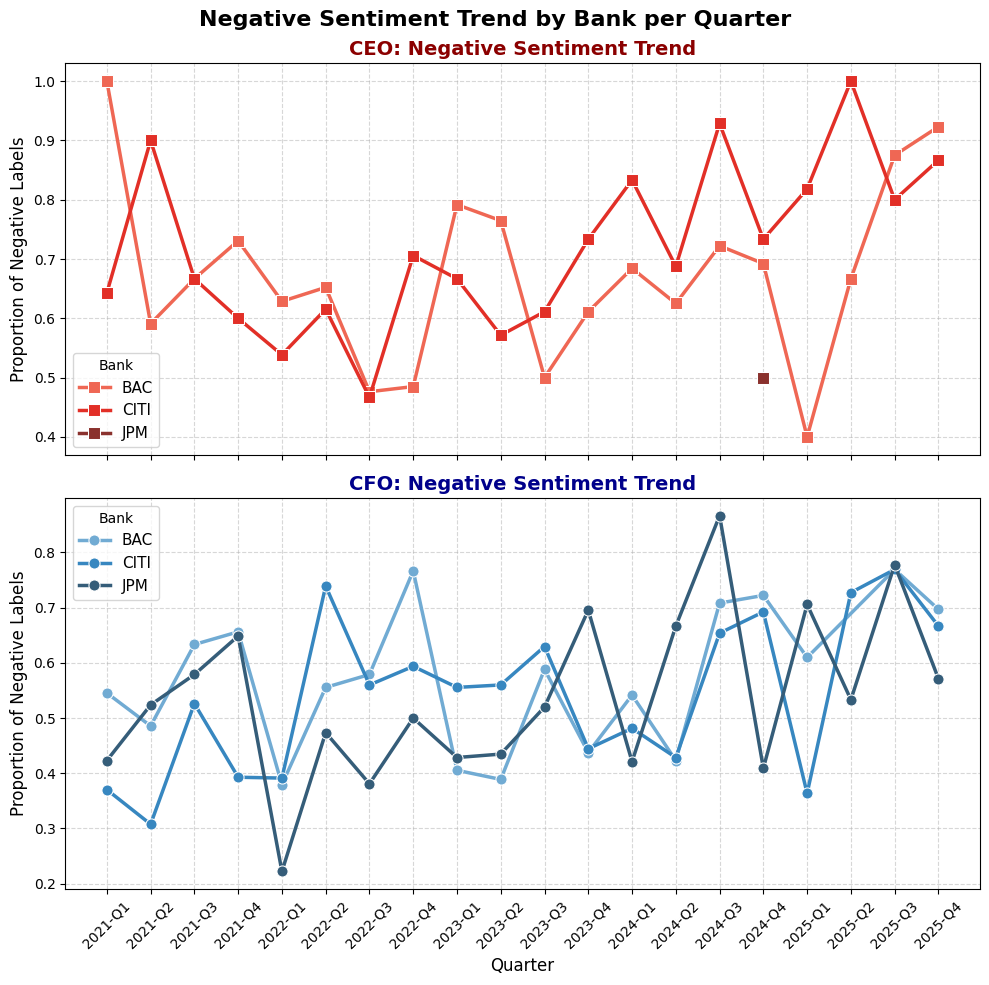

In [ ]:
# Filter to keep only the negative sentiment category
negative_share_only = finbert_counts_quarter_df[finbert_counts_quarter_df['predicted_sentiment']=='negative']
negative_share_only_CFO = negative_share_only[negative_share_only['speaker_role']=='CFO'].reset_index(drop=True)
negative_share_only_CEO = negative_share_only[negative_share_only['speaker_role']=='CEO'].reset_index(drop=True)

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharex=True)

# ----------------- FIRST SUBPLOT (Top Row) -----------------
sns.lineplot(
    data=negative_share_only_CEO,
    x='fiscal_period',
    y='proportion',
    hue='bank',
    marker='s',
    linewidth=2.5,
    markersize=8,
    palette='Reds_d',
    ax=axes[0]
)

axes[0].set_title('CEO: Negative Sentiment Trend', fontsize=14, fontweight='bold', color='darkred')
axes[0].set_ylabel('Proportion of Negative Labels', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Bank', fontsize=11)

# ----------------- SECOND SUBPLOT (Bottom Row) -----------------
sns.lineplot(
    data=negative_share_only_CFO,
    x='fiscal_period',
    y='proportion',
    hue='bank',
    marker='o',
    linewidth=2.5,
    markersize=8,
    palette='Blues_d',
    ax=axes[1]
)

axes[1].set_title('CFO: Negative Sentiment Trend', fontsize=14, fontweight='bold', color='darkblue')
axes[1].set_xlabel('Quarter', fontsize=12)
axes[1].set_ylabel('Proportion of Negative Labels', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Bank', fontsize=11)

# Rotate the bottom x-axis ticks
axes[1].tick_params(axis='x', rotation=45)

# --------------------------------------------------------
plt.suptitle('Negative Sentiment Trend by Bank per Quarter', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('Negative_Sent_Trends_Bank.svg')
plt.show()


Across all three banks, the negative sentiment percentage shows a large variation but typically hovers near 50-60%. The presence of a baseline demonstrates that defensive topics (e.g credit provisions, expense controls, and structural cost-cutting) form the basis of banking communications, even during stable quarters.

### 4.2.5 Top 10 "Hedging" Keywords in Negative Sentiment Chunks

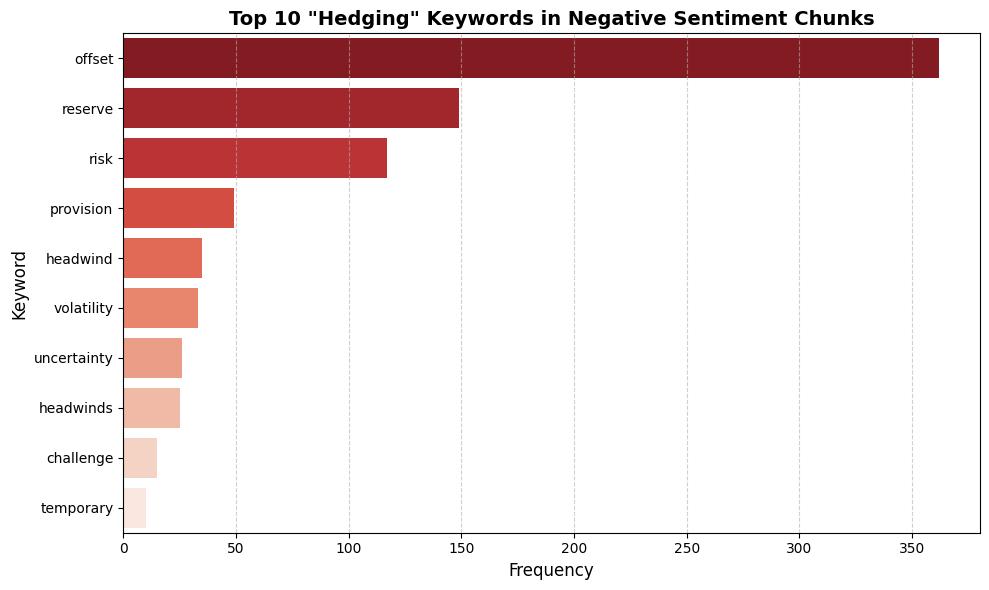

In [ ]:
# Define target hedging/defensive keywords
hedging_words = [
    'offset', 'mitigate', 'provision', 'reserve', 'uncertainty',
    'cautious', 'challenge', 'volatility', 'headwinds', 'temporary',
    'disruption', 'headwind', 'cautiously', 'unpredictable', 'risk'
]

# Filter to get sentence chunks categorized as negative by FinBERT
negative_sentence_chunks = prepared_remarks_chunked_df[prepared_remarks_chunked_df['predicted_sentiment'] == 'negative']['sentence_chunks'].dropna()

# Count frequencies of the specified hedging keywords in the negative chunks
keyword_counts = Counter()
for chunk in negative_sentence_chunks:
    text_lower = str(chunk).lower()
    for word in hedging_words:
        # Match whole words to avoid partial matches (e.g., 'provisions' using word boundaries or manual plural handling)
        matches = re.findall(rf'\b{word}s?\b', text_lower)
        keyword_counts[word] += len(matches)

# Convert to DataFrame for plotting
hedging_df = pd.DataFrame(keyword_counts.most_common(10), columns=['Keyword', 'Frequency'])

# Plot the top 10 hedging keywords
plt.figure(figsize=(10, 6))

sns.barplot(
    data=hedging_df,
    x="Frequency",
    y="Keyword",
    hue="Keyword",  # Explicitly link hue to your x-variable
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 "Hedging" Keywords in Negative Sentiment Chunks', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Keyword', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Hedging_Keywords.svg')
plt.show()


Focussing on the topmost frequently used hedging words:

**1.'Offset' (~360 occurrences)**

The term offset is overwhelmingly the most frequent hedging word. In financial transcripts, "offset" is used to neutralize negative news with positive results, or vice versa (e.g., "strong revenue was offset by rising credit card write-offs" or "expense growth offset by structural efficiencies").  (Loughran & McDonald, 2011)
    
When the frequency of "offset" begins to spike quarter-on-quarter (QoQ), it can indicate that management is struggling to deliver "pure" positive developments, forcing them to balance positive headlines with operational friction.

**2.'Reserve' (150) and 'Risk' (120)**

Both terms rank second and third, representing structural balance sheet adjustments and macro conditions.
    
An increase in the mention of "reserve" and "risk"—specifically in negative chunks—typically means the bank is actively defending its balance sheet against souring loan portfolios or expanding macroeconomic risks. (Campbell et al., 2014)

**3.The 'Headwind' (25) and 'Volatility' (25)**

Keywords like headwind(s), volatility, and uncertainty appear frequently as external excuses for poor performance or conservative guides. (Baginski et al, 2004)
   
If these vocabulary metrics increase while peer banks' hedging vocabularies remain flat, it can signal idiosyncratic execution challenges within that specific bank rather than just industry-wide macro problems.


## 4.3 FinBERT versus Llama 3.1: classification report analysis.

To perform the classification analysis, we make the assumption that the labels assigned by the Llama 3.1 8B Instruct model are the true labels, for the Llama model has been trained using the RLHF approach.

While the assumption by itself is not entirely valid and merely serves as an educated guess, it gives us the opportunity to make direct comparisons across label proportions simply using confusion matrices.

However, it must be noted that one of the aspirations of the RLHF method, which is to align a model to be helpful to humans can create a positivity bias.

Therefore, while Llama 3.1 8B Instruct is used to replace domain expert labels, it may act as a financial analysts with an unusually positive outlook.

### 4.3.1 Confusion Matrix Classification Approach

The classification approach will focus on the recall parameter which in general gives the proportion of true positive predictions out of all actual positive instances.  

In [ ]:
# Let's start with the full dataset
# Define the explicit order of  classes
target_names = ['negative', 'neutral', 'positive']

# LLM labels which are not in lower case
y_true_all_raw = prepared_remarks_chunked_df['llm_sentiment']
y_true_all = [str(label).lower() for label in y_true_all_raw]  # str() to prevent bugs if NaNs exist

# FinBERT labels
y_pred_all = prepared_remarks_chunked_df['predicted_sentiment']

# Generate and print the text-based Classification Report
print(f"--- FinBERT Classification Report for full dataset ---")

# zero_division=0 prevents crashing if a bank is missing a specific category entirely
report_all = classification_report(
      y_true_all,
      y_pred_all,
      target_names=target_names,
      zero_division=0
  )
print(report_all)

--- FinBERT Classification Report for full dataset ---
              precision    recall  f1-score   support

    negative       0.01      0.21      0.03        87
     neutral       0.60      0.43      0.50       820
    positive       0.51      0.13      0.21      1359

    accuracy                           0.24      2266
   macro avg       0.37      0.26      0.24      2266
weighted avg       0.52      0.24      0.31      2266



The classification report shows the recall for negative, neutral and positive labels is on average 21%, 43% and 13%, respectively. The highest agreement is between the neutral sentiment labels whereas the lowest is betwen positive sentiment labels. While the agreement agreement across all labels is below 50%, as if hapenned by random chance, the results are consistent with the following observations made on FinBERT (Araci, 2019):

* FinBERT cannot discern whether a statment indicates a positive outlook or merely an objective observation.

* FinBERT typically fails to do the math in which figure is higher. Therefore, in the absence of words indicative of direction like "increased", the prediction skews towards neutral.

In [ ]:
# For the confusion matrix will use row-normalized percentages:
def matrix_labels(cm):
    # Flatten the raw counts
    cm_counts = cm.flatten()

    # Calculate percentages relative to the True Class row totals (Recall per cell)
    # This divides each cell by the sum of its row
    row_sums = cm.sum(axis=1, keepdims=True)

    # Avoid division by zero if a class has no samples
    percentages = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums!=0) * 100
    cm_percentages = [f'{perc:.2f}%' for perc in percentages.flatten()]

    # Combine counts and percentages
    ini_labels = [f'Count: {count}\n({perc})' for count, perc in zip(cm_counts, cm_percentages)]

    # Reshape to a 3x3 grid for the heatmap
    cm_labels = np.asarray(ini_labels).reshape(3, 3)
    return cm_labels

By calculating normalised percentage across each row, we ensure the diagonal elements show the exact Recall percentage for each sentiment category (e.g., what % of truly negative phrases did FinBERT correctly catch).

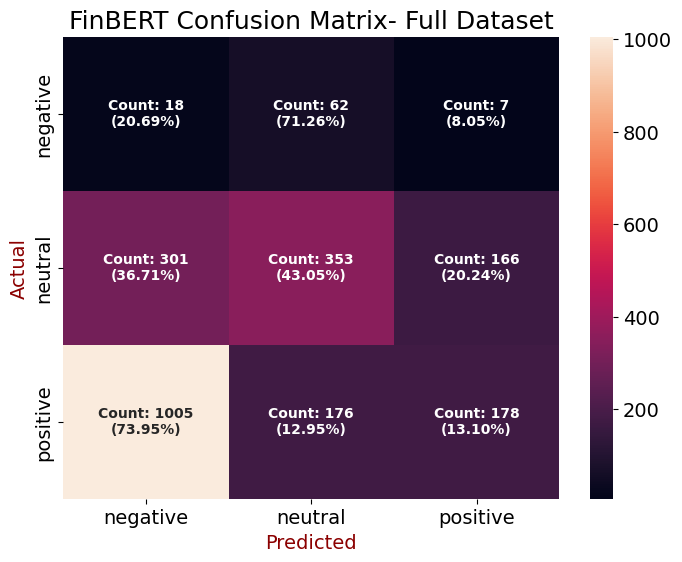

In [ ]:
# Let's visualise the recall on each target

cm_all= confusion_matrix(y_true_all, y_pred_all, labels=target_names)
cm_labels_all = matrix_labels(cm_all)

# Plot heatmap
plt.figure(figsize=(8,6))
plt.rc('font', weight='normal', size=14)
ax=sns.heatmap(
    cm_all,
    annot=cm_labels_all,
    annot_kws={"fontweight": 'bold', "size": 10},
    fmt='',
    cmap='rocket',

)

# Format axes labels
ax.xaxis.set_ticklabels(['negative', 'neutral', 'positive'],fontsize=14)
ax.yaxis.set_ticklabels(['negative', 'neutral', 'positive'],fontsize=14)

plt.xlabel('Predicted',fontsize=14,color='darkred')
plt.ylabel('Actual',fontsize=14,color='darkred')
plt.title('FinBERT Confusion Matrix- Full Dataset',fontsize=18)
# plt.savefig('Fin_Class_full.svg')
plt.show()


Let's look at the differences in sensitivity of the FinBERT model between the 3 banks:

In [ ]:
# Recall the order of classes
# target_names = ['negative', 'neutral', 'positive']

# Group by Bank
for bank_name, bank_group in prepared_remarks_chunked_df.groupby('bank'):

    print("\n" + "="*50)
    print(f"BANK: {bank_name}")
    print("="*50)

    # Isolate and lowercase the LLM labels for this specific bank
    y_true_raw = bank_group['llm_sentiment']
    y_true = [str(label).lower() for label in y_true_raw]  # str() to prevent bugs if NaNs exist

    # Isolate FinBERT labels for this specific bank
    y_pred = bank_group['predicted_sentiment']


    # Generate and print the text-based Classification Report
    print(f"--- FinBERT Classification Report for {bank_name} ---")

    # zero_division=0 prevents crashing if a bank is missing a specific category entirely
    report = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        zero_division=0
    )
    print(report)



BANK: BAC
--- FinBERT Classification Report for BAC ---
              precision    recall  f1-score   support

    negative       0.00      0.14      0.01        21
     neutral       0.57      0.43      0.49       330
    positive       0.57      0.14      0.22       689

    accuracy                           0.23      1040
   macro avg       0.38      0.24      0.24      1040
weighted avg       0.56      0.23      0.30      1040


BANK: CITI
--- FinBERT Classification Report for CITI ---
              precision    recall  f1-score   support

    negative       0.01      0.17      0.02        30
     neutral       0.59      0.43      0.50       289
    positive       0.54      0.13      0.21       489

    accuracy                           0.24       808
   macro avg       0.38      0.24      0.24       808
weighted avg       0.54      0.24      0.30       808


BANK: JPM
--- FinBERT Classification Report for JPM ---
              precision    recall  f1-score   support

    negati

* The recall for negative labels in a decreasing order by bank: JPMorgan (28%), Citigroup(17%) and Bank of America (14%).

* The recall for neutral labelsby bank: JPMorgan (43%), Citigroup(43%) and Bank of America (43%).

* The recall for positive labels in a decreasing order by bank: Bank of America (14%), Citigroup(13%) and JPMorgan (12%).


While the recall for neutral and positive labels are either same or very close for the three banks studied, the biggest difference is across the negative labels where we see the highest negative sentiment percentage across JPMorgan.

Next, let's break down the confusion matrices by bank and speaker role:

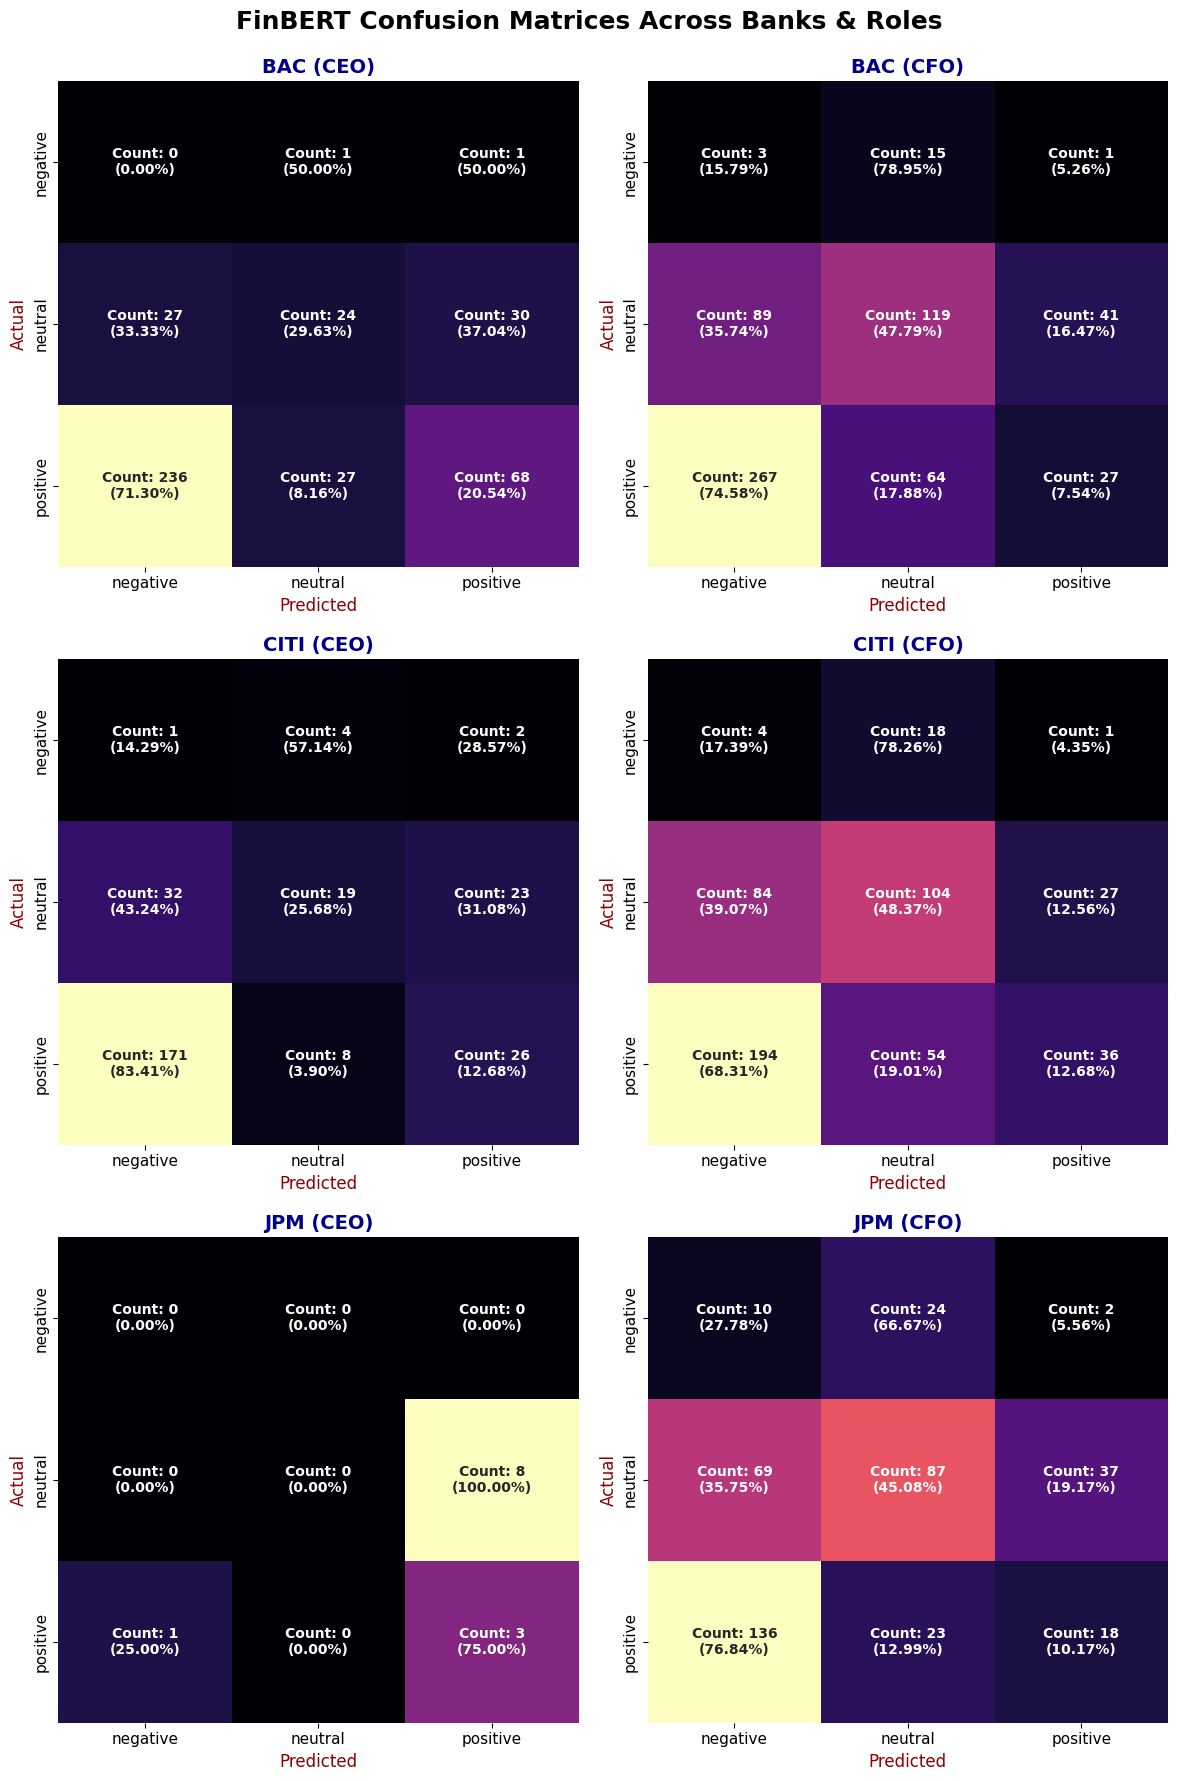

In [ ]:
# Recall the explicit order of classes
# target_names = ['negative', 'neutral', 'positive']

# Group by both bank & speaker role
# Using as_index=False ensures smooth tuple unpacking in the loop header
prepared_remarks_grouped_speaker= prepared_remarks_chunked_df.groupby(['bank', 'speaker_role'])

plt.rcParams["font.weight"] = "normal"

# Create the 3x2 Grid Layout (to fit 3 vertical panels nicely)
fig, axes = plt.subplots(3, 2, figsize=(12, 18))
axes_flat = axes.flatten()  # Flattens the 3x2 matrix into a 1D array of 6 slots

#  Iterate through groups and plot on specific grid cells
for idx, ((bank_name, role), group) in enumerate(prepared_remarks_grouped_speaker):

    # Get the specific axis subplot assigned to this index
    ax = axes_flat[idx]

    # Isolate data and generate matrix
    y_true_raw = group['llm_sentiment']
    y_true = [str(label).lower() for label in y_true_raw]
    y_pred = group['predicted_sentiment']

    cm = confusion_matrix(y_true, y_pred, labels=target_names)
    cm_labels = matrix_labels(cm)

    # Plot heatmap onto the assigned subplot cell (ax=ax)
    sns.heatmap(
        cm,
        annot=cm_labels,
        annot_kws={"fontweight": 'bold', "size": 10},
        fmt='',
        cmap='magma',
        ax=ax,
        cbar=False  # Turns off individual colorbars to keep the grid clean
    )

    # Configure axes layout parameters
    ax.xaxis.set_ticklabels(target_names, fontsize=11)
    ax.yaxis.set_ticklabels(target_names, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=12,color='darkred')
    ax.set_ylabel('Actual', fontsize=12,color='darkred')
    ax.set_title(f'{bank_name} ({role.upper()})', fontsize=14, fontweight='bold',color='darkblue')

# Adjust spacing and show the single combined figure window
plt.suptitle('FinBERT Confusion Matrices Across Banks & Roles', fontsize=18, y=0.99, fontweight='bold')
plt.tight_layout()
# plt.savefig('Fin_Class_Bank.svg')
plt.show()



Note that the label proportions have not been corrected for the number of appearances made by an executive.

* When we isolate the few number of CEO remarks from the JPMorgan dataset, the results remain similar, with both the positive and neutral recall rates shifting by less than 2%.

* In the case of the Citigroup, the agreement between the negative sentiments is higher for the CFO (17.4% compared to 14.3%). The same is also true for the neutral sentiments which have a CFO-to-CEO comparison of 48.4% to 25.7%. The positive sentiment (recall) scores remain the same for both executives.

* There appears to be a more stark difference between the executive recall rates obtained for the Bank of America. The negative sentiment recall rates differ by 15.8% in favour of the CFO; the neutral sentiment recall rates differ by ~ 18.2% in favour of the CEO; and the positive sentiment recall rates differ by 13% in favour of the CEO.

The observation that CFO neutral labels show more agreement may have to do with the said inability of FinBERT to do the math, when CFO is the executive who discloses the big headlines and the banking specific financial metrics.

It can also be argued that while FinBERT is able to detect when the sentiment and tone in language is sounding positive or negative, it is still prone to missing the underlying context, especially in cases where the statements are sugar coated or when there is a case of double negativity (i.e. when a downward word yields a positive outcome, e.g. 'reducing net loss').

Other reported weakness include trigger-word sensitivity. For example if the word 'fall' is used to mean fall within a given range when citing a financial metric, FinBERT will put a very heavy weight on the word 'fall' classifying a neutral statement as negative. Similarly, in a sentence where a company reports 'growing despite challenges faced', FinBERT will again heavily focus on the word challenge. It may also misinterpret the true subject of a matter. For instance, if a competitor firm is being mentioned in a sentence in a negative tone, FinBERT cannot distinguish what that means for the company holding the earings call transcript.

The sugar coating is also a problem for the Llama model, as would perhaps be for a person not well-versed in the financial jargon. For instance, in the case of the CEO who is more likely to put a positive spin on strategic outlook, we observe either very low or no negative label counts.

### 4.3.2 Direct comparison of quarterly trends across the 3 banks:



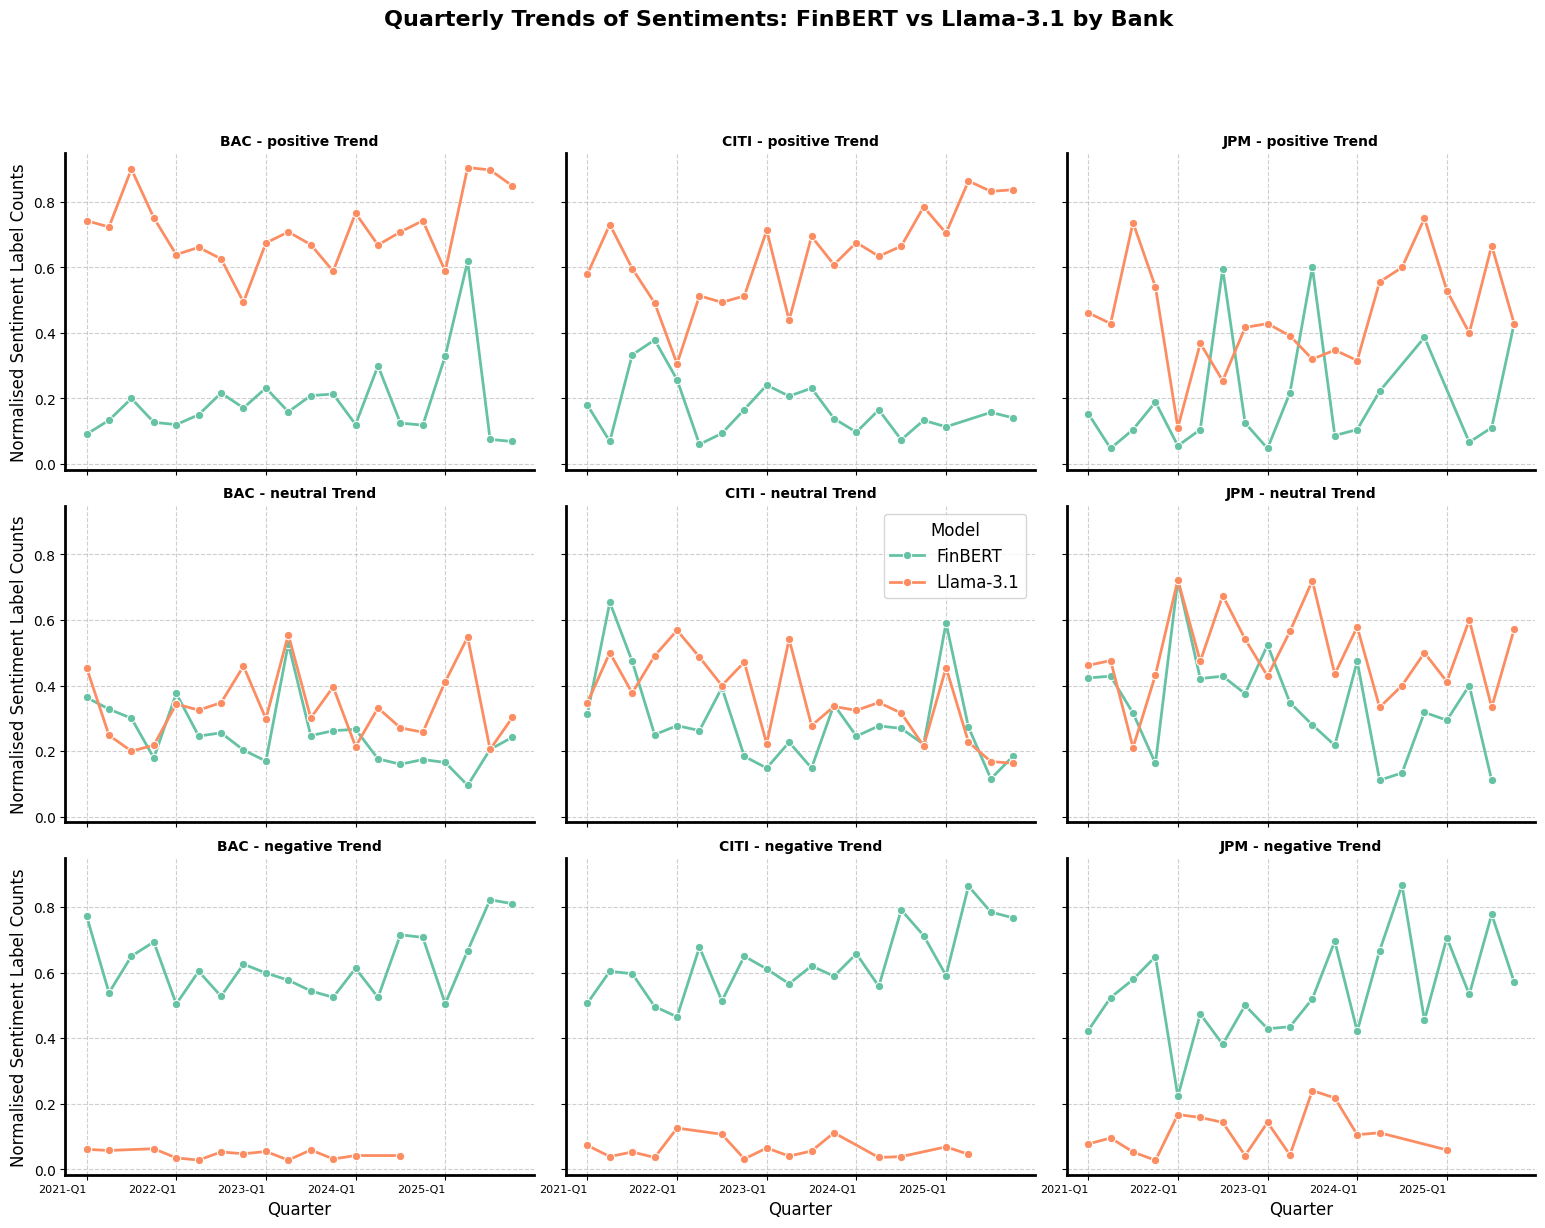

In [ ]:
# Calculate yearly percentages of each sentiment label per bank and speaker role

# Get LLM label counts

llm_counts_quarter= get_label_counts(prepared_remarks_labelled_df,
                                      groupby_cols=['bank', 'fiscal_period'],
                                      target_col='llm_sentiment', normal='True')

# Convert to a dataframe with appropriate labels

llm_counts_quarter_df = (pd.DataFrame(llm_counts_quarter)
                            .stack().reset_index()
                            .rename(columns={"llm_sentiment":"predicted_sentiment","level_3": "speaker_role", 0: "proportion"})
                            )

# Convert the sentiment column to lowercase
llm_counts_quarter_df["predicted_sentiment"] = llm_counts_quarter_df["predicted_sentiment"].str.lower()

# Add a source identifier column to each data frame
finbert_counts_quarter_df["model"] = "FinBERT"
llm_counts_quarter_df["model"] = "Llama-3.1"

# Combine into a single data frame
combined_df = pd.concat([finbert_counts_quarter_df, llm_counts_quarter_df]).reset_index(drop=True)

# Set plotting theme
sns.reset_orig()

# Create a FacetGrid with banks as columns and sentiments as rows to map trends cleanly
g = sns.FacetGrid(
    combined_df,
    row="predicted_sentiment",
    col="bank",
    hue="model",  # This splits the data into two lines per axis
    palette="Set2",  # Changed to a distinct qualitative palette for comparison
    height=4,
    aspect=1.3,
    sharey=True,
    row_order=["positive", "neutral", "negative"],
)

g.map_dataframe(sns.lineplot, "fiscal_period", "proportion", marker="o", linewidth=2, markersize=6,errorbar=None)

# Style layout and labels
g.set_axis_labels("Quarter", "Normalised Sentiment Label Counts",fontsize=12)
g.set_titles("{col_name} - {row_name} Trend",fontsize=16,weight='bold')

# Grab the 5th axis subplot from the grid array
fifth_ax = g.axes.flat[4]

# Apply the legend constraints directly to this specific axis
fifth_ax.legend(
    title="Model",
    fontsize=12,
    title_fontsize=12,
    loc="upper right"
)
chronological_quarters = sorted(combined_df['fiscal_period'].unique())

# Adjust x-ticks to display only actual years
for ax in g.axes.flat:
    ax.set_xticks(range(len(chronological_quarters)))
    ax.set_xticklabels(chronological_quarters, rotation=45, ha='right', fontsize=8)
    # Get current ticks and labels
    ticks = ax.get_xticks()
    labels = [label.get_text() for label in ax.get_xticklabels()]

    # Apply every 4th tick and label
    ax.set_xticks(ticks[::4])
    ax.set_xticklabels(labels[::4], rotation=0)

    ax.grid(True, linestyle='--', alpha=0.6)
    for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Quarterly Trends of Sentiments: FinBERT vs Llama-3.1 by Bank", fontsize=16, weight='bold', y=1.02)
# plt.savefig('Quarterly_Sent_Trends_Model.svg')
plt.show()

As expected, the proportion of neutral labels presented across the fiscal quarters for both the Llama 3.1 and the FinBERT models overlap, while the negative labels always remain separated.

Focusing on the positive label trends, the discrepancy is the largest for the Bank of America dataset and smallest for the JPMorgan dataset. This is likely due to there being less instances of positive sentiment for the JPMorgan dataset.

Turning back to the negative label trends, the discrepancy is once again smaller for the JPMorgan dataset, while we see that the proportion of negative labels given by the FinBERT model is consistently higher than that of the Llama 3.1 which may have a slight positivity bias.

## 4.4 The evolution of the Llama 3.1 topic distributions obtained per bank.

In [ ]:
# Group by the time period and topic, then count the occurrences for each role
llm_topics = (
    prepared_remarks_chunked_df.groupby(["bank","fiscal_period", "speaker_role","primary_topic"])
    .size()
    .reset_index(name="Count")
)

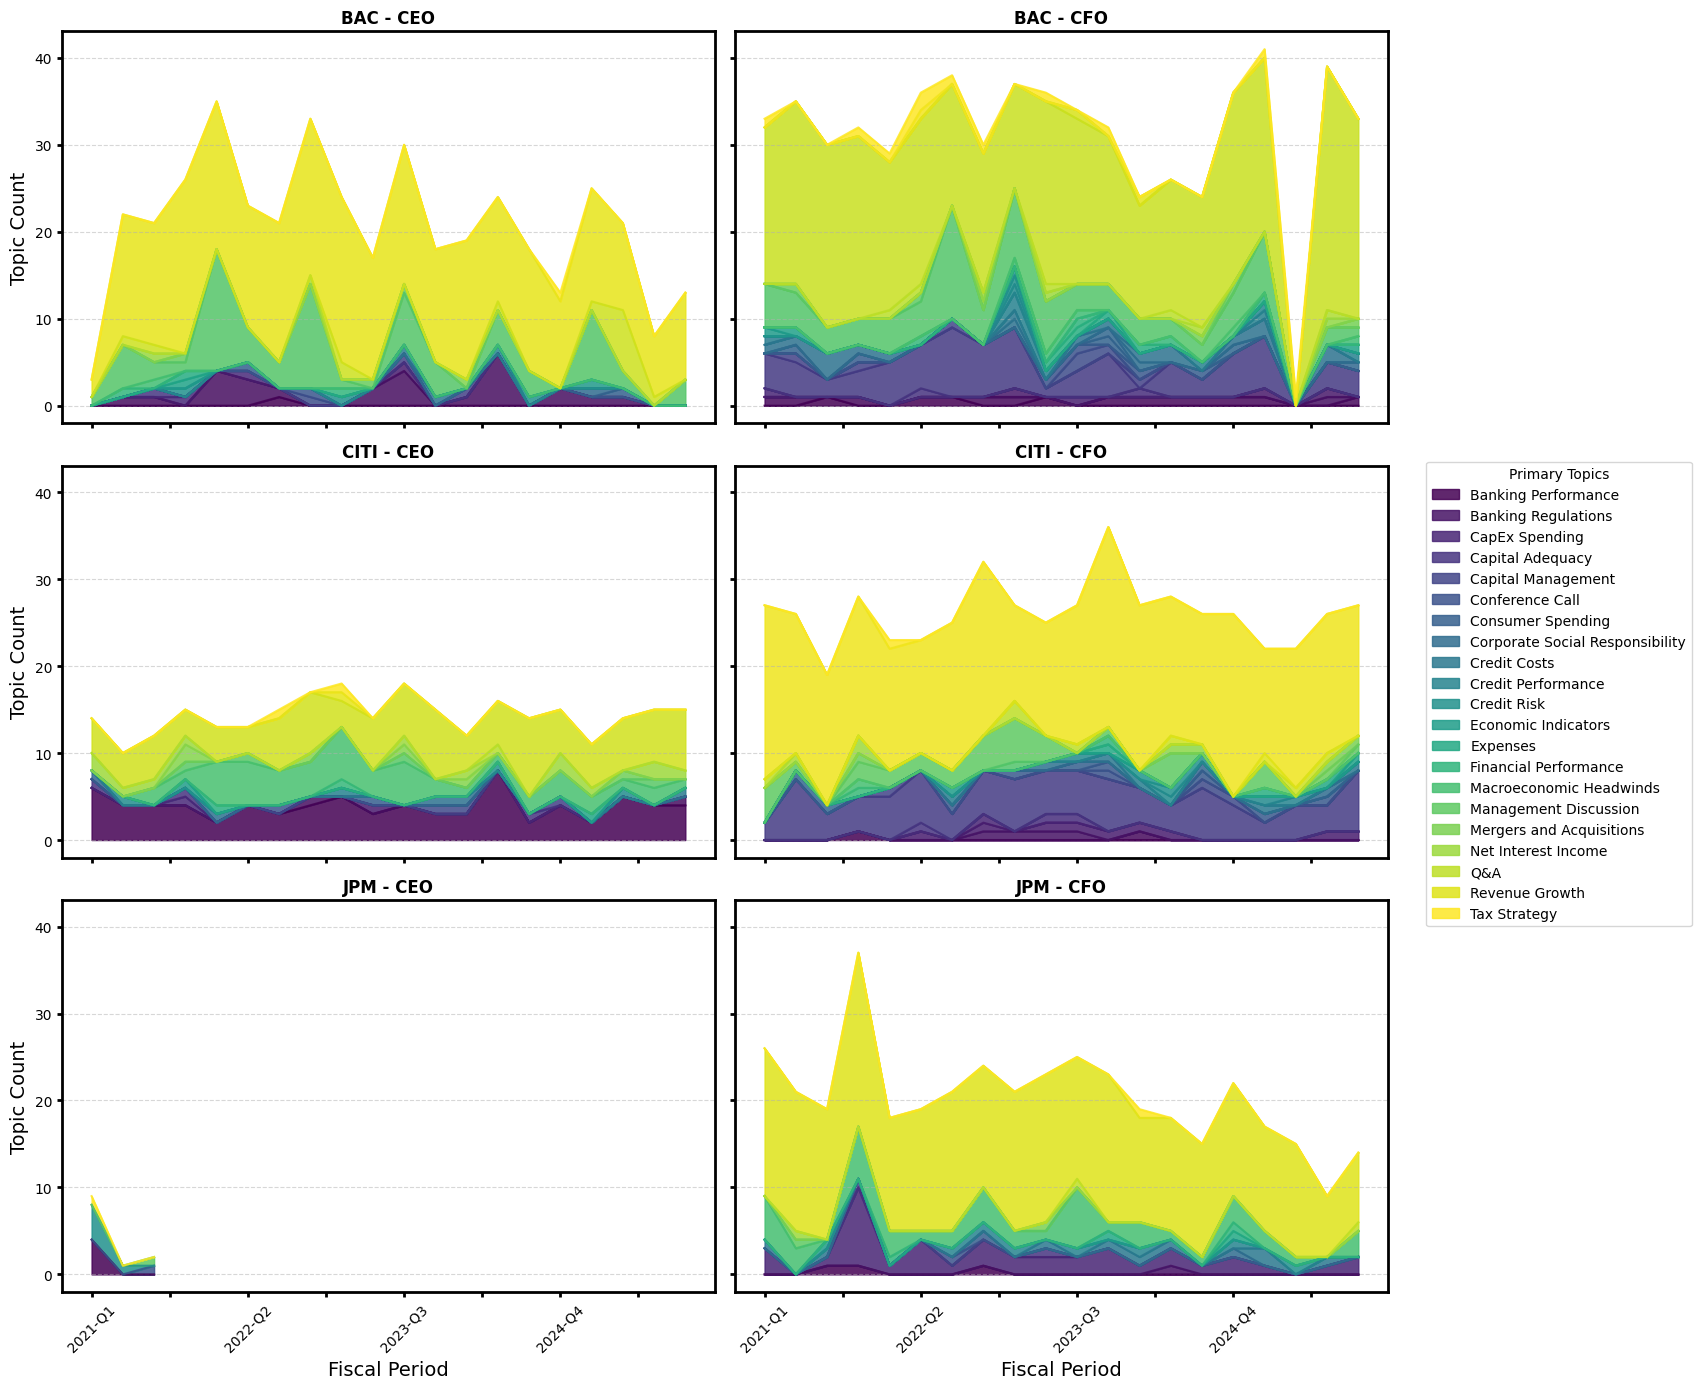

In [ ]:
# Define the dimensions

banks = ["BAC", "CITI", "JPM"]
roles = ["CEO", "CFO"]

# Initialize the 3 rows x 2 columns grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 14), sharex=True, sharey=True)

# Define a shared colormap for all subplots so the legend stays consistent
cmap = plt.get_cmap("viridis")

# Loop through rows (banks) and columns (roles) ---
for row_idx, bank in enumerate(banks):
    for col_idx, role in enumerate(roles):

        # Get the specific subplot axis handle
        ax = axes[row_idx, col_idx]

        # Filter the unpivoted dataset down to the current Bank + Role box
        subset = llm_topics[
            (llm_topics["bank"] == bank) &
            (llm_topics["speaker_role"] == role)
        ]

        # Pivot the filtered data locally for this specific plot panel
        pivot_df = subset.pivot(
            index="fiscal_period",
            columns="primary_topic",
            values="Count"
        ).fillna(0)

        # If data exists for this combination, paint the stacked area chart
        if not pivot_df.empty:
            pivot_df.plot(
                kind="area",
                stacked=True,
                ax=ax,
                cmap=cmap,
                alpha=0.85,
                legend=False # Suppress individual legends inside the grid boxes
            )

        # Design individual grid box elements
        ax.set_title(f"{bank} - {role}", fontsize=12, fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        ax.tick_params(axis='x', rotation=45)
        # Change spine (axis line) outline thickness to 2
        for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

        # Increase tick visibility
        ax.tick_params(width=2)
        ax.tick_params(axis='y', labelsize=10)
        ax.tick_params(axis='x', labelsize=10)

        # Label only the outer edges to keep the visual grid uncluttered
        if col_idx == 0:
            ax.set_ylabel("Topic Count", fontsize=14)
        if row_idx == 2:
            ax.set_xlabel("Fiscal Period", fontsize=14)

# Global Titles and a Single Unified Legend ---
# plt.suptitle("Evolution of Earnings Call Topics Over Fiscal Quarters", fontsize=16, fontweight="bold", y=1)

# Grab the labels to construct one global legend
handles, labels = ax.get_legend_handles_labels()

# bbox_to_anchor places it perfectly inside the newly cleared right margin
fig.legend(handles, labels, title="Primary Topics", loc="center left", bbox_to_anchor=(0.89, 0.5))

# rect parameter keeps subplots within 0 to 0.88 horizontal space
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig('TopicEvo.svg')
plt.show()

The results show a range of topics that are discussed within the prepared remarks section which can be several pages long. As well as various financial metrics quoted (e.g. credit costs,CapEX spending), there are themes of strategic outlook in various financial sectors and markets (e.g. mergers and acqusitions, revenue growth,tax strategy).

The colour map indicates topic prevalancy and show how topics like tax strategy, revenue growth, mergers and acquisitions as well as net income dominate discussions QoQ, across all banks (even for the JPM CEO who rarely takes part in prepared remarks). We also see phrases like Q&A session and management discussion make it to the list, since there are several sentence chunks prevailing the Q&A session or greeting the attendees.

Another intresting aspect is the similarity between topic titles such as in the case of capital management and adequacy. This could be the result of a topic being mentioned in one sentence chunk and continuing in the next with different aspects of the topic now introduced.

## 4.5 Distribution of sentiment labels across broader topics.

In [ ]:
print(len(prepared_remarks_chunked_df['primary_topic'].unique()))

110


Since there are 110 unique primary topics identified, some of which sound similar, we will perform a basic hierarchical topic clustering using an open source embedding model.

In [ ]:
# Get unique topics
unique_topics = prepared_remarks_chunked_df['primary_topic'].dropna().unique().tolist()

# Convert text topics into vector embeddings
# Using a fast, lightweight open-source embedding model
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(unique_topics)

# Use hierarchical clustering to group them by distance
# Adjust distance_threshold lower for strict matching, higher for broader groups
clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.6,
    metric='cosine',
    linkage='average'
)
cluster_labels = clustering.fit_predict(embeddings)

# Map each cluster to a dominant parent topic
cluster_map = pd.DataFrame({'topic': unique_topics, 'cluster': cluster_labels})

# Auto-assign the shortest topic title in the cluster as the 'Parent Name'
parent_topics = cluster_map.groupby('cluster')['topic'].agg(lambda x: min(x, key=len)).to_dict()
cluster_map['combined_topic'] = cluster_map['cluster'].map(parent_topics)

# Merge these smart groups back into your main DataFrame
topic_lookup = dict(zip(cluster_map['topic'], cluster_map['combined_topic']))
prepared_remarks_chunked_df['combined_topic'] = prepared_remarks_chunked_df['primary_topic'].map(topic_lookup)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Essentially, the embedding approach converts the acquired raw topics into vectors and automatically groups similar phrases based on semantic meaning.

In [ ]:
print(prepared_remarks_chunked_df['combined_topic'].unique())

['Taxation' 'Balance Sheet' 'Expense' 'Economic Indicators' 'Credit'
 'Liquidity' 'Digital Engagement' 'R&D Investment' 'Human Capital'
 'Social Responsibility' 'Human Resources' 'People/Leadership'
 'Asset Quality' 'Operating Leverage' 'Conference Call'
 'Regulatory Capital' 'CET1 requirement' 'Net Interest Income'
 'Earnings Call' 'People and Technology Costs' 'Q&A' 'Deposit Base'
 'Customer Base' 'Hold-to-Maturity Securities'
 'ESG (Environmental, Social, and Governance)' 'People Movement'
 'M&A/Restructuring' 'Supply Chain Logistics' 'Divestitures'
 'RWA Management']


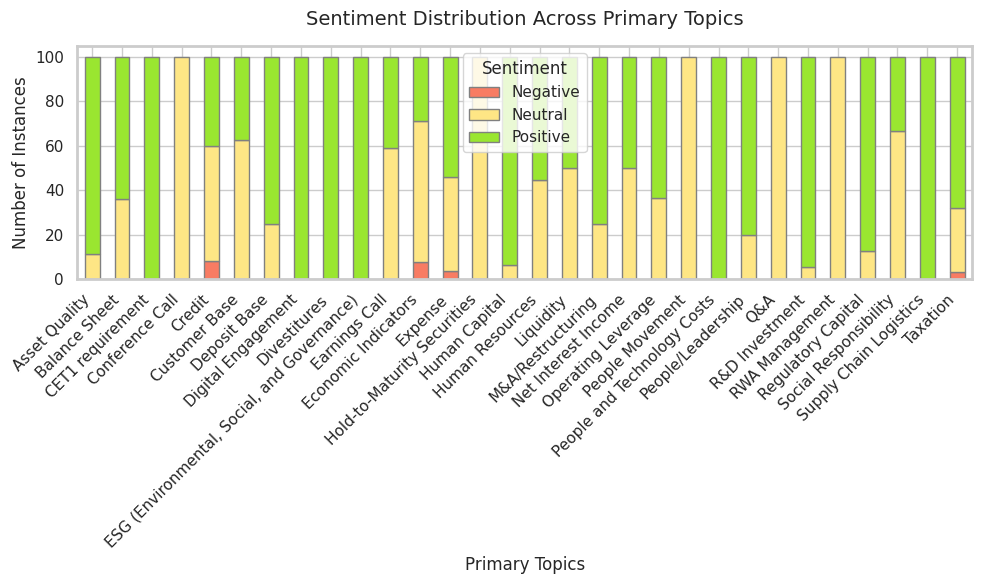

In [ ]:
# Create a contingency table (cross-tabulation)
sentiment_cont = pd.crosstab(prepared_remarks_chunked_df['combined_topic'], prepared_remarks_chunked_df['llm_sentiment'],normalize='index') * 100

# Reorder columns to a logical order (Negative -> Neutral -> Positive)
sentiment_order = ['Negative', 'Neutral', 'Positive']

# Plot the stacked bar chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sentiment_cont.plot(
    kind='bar',
    stacked=True,
    color=['#F87C63', '#FEE685', '#9AE630'],
    edgecolor='gray',
    ax=ax
)

for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

ax.set_title('Sentiment Distribution Across Primary Topics', fontsize=14, pad=15)
ax.set_xlabel('Primary Topics', fontsize=12)
ax.set_ylabel('Number of Instances', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
# plt.savefig('SentimentDistTopics.svg')
plt.show()

Looking at the distribution of labels across the broadly clustered topics, we see a dominance of neutrality and poisitivity again. The only few topics that indicate negativity appear under 'Credit', 'Expense','Economic Indicators' (i.e. based on directionality of the figures, financial metrics being quoted) and 'Taxation' which is generally an unpleasant topic to discuss.

It must be noted that the diversity and large number of topics picked-up by the Llama 3.1 model (even after clustering) means majority of themes have low frequency counts, albeit row-wise normalisaton has been applied.

## 5.0 Conclusions:



The analysis shows a significant discrepancy between the sentiment labels assigned by the Llama 3.1 8B Instruct and FinBERT models, where both models have known weaknesses.

FinBERT cannot do the math on quoted figures to understand directionality and focuses on trigger words more than the context. It can indeed be said to have a negativity bias.

Llama 3.1 8B Instruct on the other hand has a positivity bias and is prone to the 'sugar-coating' problem.

However, the RLHF training of the larger Llama model makes it superior when it comes to zero-shot classification (2511.13983v1 [cs.CE],2403.12285v1 [cs.CL],Kirtac and Germano, 2025). It also offers transparency through reasoning and allows tracking of the decisions made.

The study can be extended to include comparisons between the Google's Gemma3:4b and Open AI's GPT models, as there is clearly value in improving FinBERT's stand alone performance through diversification ([ref](https://tommijohnsen.substack.com/p/finbert-is-wrong-83-of-the-time-on?utm_campaign=post-expanded-share&utm_medium=web)).